## Dependencies

In [135]:
# connect to Google Drive to import the training data
# from google.colab import drive
# drive.mount('/content/drive')

In [136]:
# install dependencies if the notebook is run on Colab
# !pip install emoji mlflow optuna contractions gensim

In [137]:
# install dependencies if the notebook is run on Kaggle
# !pip install mlflow --quiet contractions

In [138]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# import torch
import re
import time
import copy
import html
import emoji
import random
import mlflow
import optuna
# import keras
import nltk
import json
# import tensorflow as tf
from tqdm import tqdm
# from contractions import fix
# from tensorflow.keras.preprocessing.text import Tokenizer
# from tensorflow.keras.preprocessing.sequence import pad_sequences
# from tensorflow.keras.metrics import FBetaScore
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import GRU, Embedding, Dense
# from transformers import DistilBertTokenizer, DistilBertModel
from datetime import datetime
from collections import Counter, OrderedDict
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
# from gensim.models import Word2Vec
# from gensim.utils import simple_preprocess
# from sklearn.linear_model import LogisticRegression
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.pipeline import Pipeline
# from sklearn.metrics import accuracy_score, fbeta_score, log_loss, confusion_matrix
# from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer

In [139]:
FLAGS = re.MULTILINE | re.DOTALL
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [140]:
try:
    import torch

    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("CUDA available:", torch.cuda.is_available())
    if device == "cuda":
        print("Device:", torch.cuda.get_device_name(0))
    else:
        print("Device: CPU")
except ImportError:
    device = "cpu"
    print("PyTorch is not imported yet. Continuing on CPU for the EDA section.")


PyTorch is not imported yet. Continuing on CPU for the EDA section.


In [141]:
import os

if os.getcwd() == '/kaggle/working':
    DATA_PATH = "/kaggle/input/datasets/mouhamadoudiagne/sentiment140/"
elif os.getcwd() == '/content' :
    DATA_PATH = "/content/drive/MyDrive/AI Engineer OC/Projet 7/"
else :
    DATA_PATH = '../data/'

print(f"Data Directory : {DATA_PATH}")

Data Directory : ../data/


## Exploration & Data Analysis

### Data Import

The Sentiment140 file contains encoding irregularities, so we compare three import strategies before deciding which dataframe to keep for the rest of the notebook. For each method, we audit missing values, duplicates, replacement characters, mojibake patterns, and C1 control characters, then inspect a few affected tweets when they exist.


In [142]:
# Absolute path to the raw Sentiment140 export used throughout the EDA.
DATA_FILE = DATA_PATH + "sentiment140/training.1600000.processed.noemoticon.csv"
RANDOM_STATE = 42

def make_encoding_audit(df):
    """Summarize the main quality checks for one imported dataframe."""
    tweets_col = df["tweet"].astype(str)
    replacement_mask = tweets_col.str.contains("\uFFFD", regex=False)
    mojibake_mask = tweets_col.str.contains("ï¿½", regex=False)
    c1_mask = tweets_col.apply(lambda s: any(0x80 <= ord(ch) <= 0x9F for ch in s))

    audit_summary = pd.Series({
        "nb_rows": len(df),
        "nb_missing_values": int(df.isnull().sum().sum()),
        "nb_rows_with_missing_values": int(df.isnull().any(axis=1).sum()),
        "nb_duplicated_rows": int(df.duplicated(keep="first").sum()),
        "rows_with_replacement_char": int(replacement_mask.sum()),
        "rows_with_mojibake_replacement": int(mojibake_mask.sum()),
        "rows_with_c1_control_chars": int(c1_mask.sum()),
    })

    return audit_summary, replacement_mask, mojibake_mask, c1_mask

def show_flagged_tweets(df, replacement_mask, mojibake_mask, c1_mask, sample_size=5):
    """Display sample tweets for each encoding-related anomaly when present."""
    checks = [
        ("replacement_char", replacement_mask),
        ("mojibake_replacement", mojibake_mask),
        ("c1_control_chars", c1_mask),
    ]

    for label, mask in checks:
        count = int(mask.sum())
        print(f"{label}: {count} rows")
        if count:
            display(df.loc[mask, ["target", "tweet"]].sample(min(sample_size, count), random_state=RANDOM_STATE))
        else:
            print("No matching tweet found.")


#### `utf-8` import with `encoding_errors="replace"`

This strategy forces pandas to replace undecodable byte sequences with the replacement character `�`. It is useful for auditing how much unreadable content appears when we insist on UTF-8 decoding.


In [143]:
tweets_utf8 = pd.read_csv(
    DATA_FILE,
    names=["target", "id", "datetime", "query", "username", "tweet"],
    header=None,
    encoding="utf-8",
    encoding_errors="replace"
)

tweets_utf8["tweet"] = tweets_utf8["tweet"].astype(str)
audit_summary_utf8, replacement_mask_utf8, mojibake_mask_utf8, c1_mask_utf8 = make_encoding_audit(tweets_utf8)

display(audit_summary_utf8)
show_flagged_tweets(tweets_utf8, replacement_mask_utf8, mojibake_mask_utf8, c1_mask_utf8)


nb_rows                           1600000
nb_missing_values                       0
nb_rows_with_missing_values             0
nb_duplicated_rows                      0
rows_with_replacement_char           5338
rows_with_mojibake_replacement          0
rows_with_c1_control_chars              0
dtype: int64

replacement_char: 5338 rows


,target,tweet
1012586,4,@LIinLE thx! welcome! Peg' s friends m�ssen g...
828705,4,@Formula1RO ce p?rere ai de ceea ce am scris p...
1595857,4,@Tiny_Winchester Wha…… Didn't Indiana Jones en...
1143086,4,Elope with me Miss Private and we�ll sail arou...
26702,0,"�110 up this weekend, Must...not...spend"


mojibake_replacement: 0 rows
No matching tweet found.
c1_control_chars: 0 rows
No matching tweet found.


#### `latin-1` import

This strategy decodes every byte without failing, which often preserves legacy-encoded content but can also expose mojibake and control-character artifacts.


In [144]:
tweets_latin1 = pd.read_csv(
    DATA_FILE,
    names=["target", "id", "datetime", "query", "username", "tweet"],
    header=None,
    encoding="latin-1"
)

tweets_latin1["tweet"] = tweets_latin1["tweet"].astype(str)
audit_summary_latin1, replacement_mask_latin1, mojibake_mask_latin1, c1_mask_latin1 = make_encoding_audit(tweets_latin1)

display(audit_summary_latin1)
show_flagged_tweets(tweets_latin1, replacement_mask_latin1, mojibake_mask_latin1, c1_mask_latin1)


nb_rows                           1600000
nb_missing_values                       0
nb_rows_with_missing_values             0
nb_duplicated_rows                      0
rows_with_replacement_char              0
rows_with_mojibake_replacement       4051
rows_with_c1_control_chars           5858
dtype: int64

replacement_char: 0 rows
No matching tweet found.
mojibake_replacement: 4051 rows


,target,tweet
996059,4,1 mï¿½s beeeem bonitinho!
23584,0,"@twilightPsycho ohh I have to wait more, in Sp..."
888729,4,Toys 4 boyz...lotï¿½s of great cars...pretty g...
940527,4,Is watching the last how i met your mother ï¿½...
1048820,4,"I'm about to jump in my pool, it's 30ï¿½ C and..."


c1_control_chars: 5858 rows


,target,tweet
1516362,4,[Todd Rundgren â Hello It's Me] @Quazatron ...
1345440,4,Getting a little silly now â« http://blip.fm...
656760,0,@Shaker_ ØªØ­Ø²Ø²Ø²Ø²Ø²Ù
245409,0,"okeei, whay all the men has to be like this?? ..."
1388858,4,@Dmitry_vi Good mornin' ÐÐ° Ð±ÑÐ´ÑÑ Ð²ÑÑ...


#### `cp1252` import

This strategy is often a better fit for legacy Western punctuation than `latin-1`. We will use it as the working dataframe for the rest of the notebook.


In [145]:
tweets_cp1252 = pd.read_csv(
    DATA_FILE,
    names=["target", "id", "datetime", "query", "username", "tweet"],
    header=None,
    encoding="cp1252"
)

tweets_cp1252["tweet"] = tweets_cp1252["tweet"].astype(str)
audit_summary_cp1252, replacement_mask_cp1252, mojibake_mask_cp1252, c1_mask_cp1252 = make_encoding_audit(tweets_cp1252)

display(audit_summary_cp1252)
show_flagged_tweets(tweets_cp1252, replacement_mask_cp1252, mojibake_mask_cp1252, c1_mask_cp1252)


nb_rows                           1600000
nb_missing_values                       0
nb_rows_with_missing_values             0
nb_duplicated_rows                      0
rows_with_replacement_char              0
rows_with_mojibake_replacement       4051
rows_with_c1_control_chars              0
dtype: int64

replacement_char: 0 rows
No matching tweet found.
mojibake_replacement: 4051 rows


,target,tweet
996059,4,1 mï¿½s beeeem bonitinho!
23584,0,"@twilightPsycho ohh I have to wait more, in Sp..."
888729,4,Toys 4 boyz...lotï¿½s of great cars...pretty g...
940527,4,Is watching the last how i met your mother ï¿½...
1048820,4,"I'm about to jump in my pool, it's 30ï¿½ C and..."


c1_control_chars: 0 rows
No matching tweet found.


In [146]:
tweets = tweets_cp1252.copy()
tweets["tweet_raw"] = tweets["tweet"]
tweets.head()

,target,id,datetime,query,username,tweet,tweet_raw
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t...","@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all....","@nationwideclass no, it's not behaving at all...."


The comparison above gives us a concrete view of how each import strategy alters the corpus. Unless later inspection suggests otherwise, the rest of the notebook uses the `cp1252` import stored in `tweets`.


### Sampling Strategy

The original dataset contains **1.6 million tweets** labelized by the `target` column which assigns `0` for *negative* tweets and `4` for *positive* tweets. To keep the experiments tractable while preserving the class balance, we build a reproducible sample of 100,000 rows with exactly the same number of positive and negative tweets.

In [147]:
# The downstream experiments use a balanced 100k subset to keep training tractable.
SAMPLE_SIZE = 100_000
RANDOM_STATE = 42
sample_per_class = SAMPLE_SIZE // tweets["target"].nunique()

# Stratified sampling keeps the positive/negative balance identical to the full dataset.
data = (
    tweets.groupby("target", group_keys=False)
    .sample(n=sample_per_class, random_state=RANDOM_STATE)
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
    .copy()
)

data.head()


,target,id,datetime,query,username,tweet,tweet_raw
0,4,1759275984,Sun May 10 18:51:25 PDT 2009,NO_QUERY,HeiddiZ,@jesslaw that was my first broadway show. Went...,@jesslaw that was my first broadway show. Went...
1,4,2046681683,Fri Jun 05 12:32:13 PDT 2009,NO_QUERY,CindyWMorrison,@onlineresume Thanks for the #FF (DAMES w/BRA...,@onlineresume Thanks for the #FF (DAMES w/BRA...
2,0,2260789126,Sat Jun 20 19:46:31 PDT 2009,NO_QUERY,Da_Wiz_Kid,N my bed aaallll alone,N my bed aaallll alone
3,4,1967551018,Fri May 29 19:47:18 PDT 2009,NO_QUERY,samanthadenea,"at work, running around like crazy! we be BUSY!","at work, running around like crazy! we be BUSY!"
4,4,2001310820,Tue Jun 02 00:28:36 PDT 2009,NO_QUERY,caldjr,morning tweeps. bit fresher today but still go...,morning tweeps. bit fresher today but still go...


In [148]:
distribution_summary = pd.DataFrame({
    "full_dataset": tweets["target"].value_counts(normalize=True).sort_index(),
    "sample": data["target"].value_counts(normalize=True).sort_index()
})
distribution_summary.index = distribution_summary.index.map({0: "negative", 4: "positive"})
(distribution_summary * 100).round(2)


,full_dataset,sample
target,,
negative,50.0,50.0
positive,50.0,50.0


### Label Meaning

According to the dataset definition, target value `0` corresponds to a negative tweet and target value `4` corresponds to a positive tweet. For binary modeling, we keep the original label in `target_original` and remap `4 -> 1` in `target`.

The examples below are only a sanity check.

In [149]:
# Sentiment140 definition: 0 = negative, 4 = positive
data["target_original"] = data["target"]
data["target"] = data["target_original"].replace({0: 0, 4: 1})


In [150]:
label_definition = pd.DataFrame({
    "target_original": [0, 4],
    "sentiment_label": ["negative", "positive"],
    "target_binary": [0, 1]
})

display(label_definition)
print("Negative examples")
display(data.loc[data["target"] == 0, ["tweet"]].sample(3, random_state=RANDOM_STATE))
print("Positive examples")
display(data.loc[data["target"] == 1, ["tweet"]].sample(3, random_state=RANDOM_STATE))


,target_original,sentiment_label,target_binary
0,0,negative,0
1,4,positive,1


Negative examples


,tweet
67034,@carrietino The 'signage' for your Open House...
18788,My nerves are wrecking my stomach. I wish it'...
395,#UFC = BF's revenge for #rhnj or my personal p...


Positive examples


,tweet
67191,Girls night out tonight! Should be a great tim...
18920,"@missamanda yeah, i'll take care of it tonight..."
403,@DaTaJoKaH it aint early lol...im doing great ...


In [151]:
# we propagate the label remapping to the whole dataset
tweets["target_original"] = tweets["target"]
tweets["target"] = tweets["target_original"].replace({0: 0, 4: 1})

### Text Length Analysis

Tweet length helps us understand the structure of the corpus and later choose sequence-length hyperparameters for neural models.

In [152]:
data["tweet_length_chars"] = data["tweet"].str.len()
data["tweet_length_words_raw"] = data["tweet"].str.split().str.len()
data["tweet_mean_words_length"] = data["tweet_length_chars"] / data["tweet_length_words_raw"]

length_summary = pd.DataFrame({
    "tweet_length_chars": data["tweet_length_chars"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
    "tweet_length_words_raw": data["tweet_length_words_raw"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]),
    "tweet_mean_words_length": data["tweet_mean_words_length"].describe(percentiles=[0.5, 0.9, 0.95, 0.99])
})
length_summary


,tweet_length_chars,tweet_length_words_raw,tweet_mean_words_length
count,100000.000000,100000.000000,100000.000000
mean,74.180490,13.188900,5.880310
std,36.623096,6.980467,1.408495
min,7.000000,1.000000,2.125000
50%,69.000000,12.000000,5.608696
90%,130.000000,23.000000,7.250000
95%,136.000000,25.000000,8.125000
99%,141.000000,28.000000,10.833333
max,369.000000,64.000000,126.000000


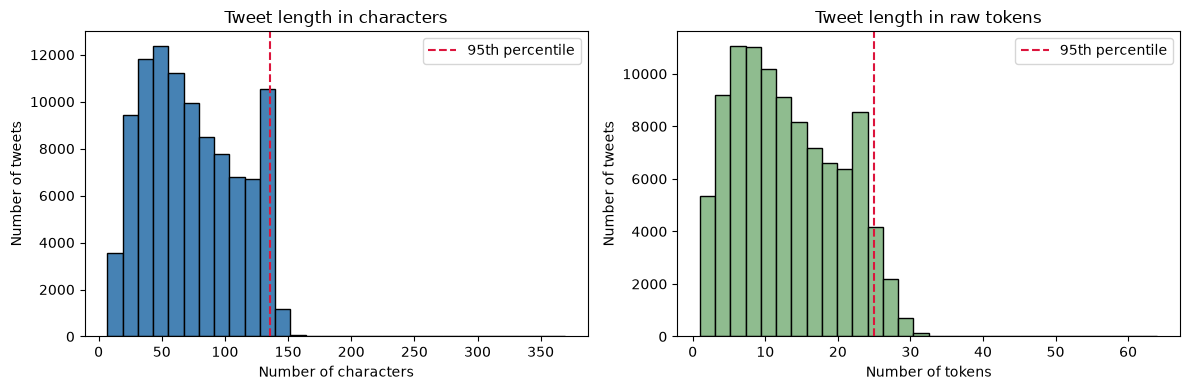

In [153]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(data["tweet_length_chars"], bins=30, color="steelblue", edgecolor="black")
axes[0].axvline(data["tweet_length_chars"].quantile(0.95), color="crimson", linestyle="--", label="95th percentile")
axes[0].set_title("Tweet length in characters")
axes[0].set_xlabel("Number of characters")
axes[0].set_ylabel("Number of tweets")
axes[0].legend()

axes[1].hist(data["tweet_length_words_raw"], bins=30, color="darkseagreen", edgecolor="black")
axes[1].axvline(data["tweet_length_words_raw"].quantile(0.95), color="crimson", linestyle="--", label="95th percentile")
axes[1].set_title("Tweet length in raw tokens")
axes[1].set_xlabel("Number of tokens")
axes[1].set_ylabel("Number of tweets")
axes[1].legend()

plt.tight_layout()
plt.show()


The length percentiles above are directly useful for the mission. They tell us whether our future sequence models can work with a relatively short maximum length or whether we risk truncating a large portion of the corpus. 

We also remark that the mean word length we calculated (**5.88**) is greater than the average word english texts(**~4.79**, see https://www.norvig.com/mayzner.html). More precisely, conversational texts have generally lesser word lengths while academic corpuses use longer words (see https://www.atlantis-press.com/article/55915653.pdf). As we are working on tweets, that relate more to conversational texts, the mean word lengths should have been shorter. The result we have may be due to special caracteristics of (uncleaned) social media texts : elongated words, uncleaned punctuations, links, emojis, etc... We can also consider the fact that social media users sometimes don't bother with spacing and can merge two successive words into one and then make it longer (e.g "good morning" and "goodmorning").

### Raw Twitter Artifact Analysis

Before looking at lexical content, we inspect the main social-media artifacts that may require dedicated preprocessing rules.

In [154]:
# Each boolean feature captures a Twitter-specific artifact we may later normalize explicitly.
data["has_url"] = data["tweet"].str.contains(r"http\S+|www\.\S+", regex=True)
data["has_mention"] = data["tweet"].str.contains(r"@\w+", regex=True)
data["has_hashtag"] = data["tweet"].str.contains(r"#\w+", regex=True)
data["has_elongation"] = data["tweet"].str.contains(r"(.)\1{2,}", regex=True)
data["has_exclamation"] = data["tweet"].str.contains(r"!", regex=True)
data["has_question_mark"] = data["tweet"].str.contains(r"\?", regex=True)

artifact_cols = [
    "has_url",
    "has_mention",
    "has_hashtag",
    "has_elongation",
    "has_exclamation",
    "has_question_mark",
]

# Aggregating by sentiment makes it easy to compare how common each artifact is by class.
artifact_summary = data.groupby("target")[artifact_cols].mean().mul(100).round(1)
artifact_summary.index = artifact_summary.index.map({0: "negative", 1: "positive"})
artifact_summary.index.name = "sentiment"
artifact_summary


C:\Users\Dell\AppData\Local\Temp\ipykernel_24048\86806142.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  data["has_elongation"] = data["tweet"].str.contains(r"(.)\1{2,}", regex=True)


,has_url,has_mention,has_hashtag,has_elongation,has_exclamation,has_question_mark
sentiment,,,,,,
negative,3.1,38.0,1.9,29.6,25.1,10.2
positive,6.3,54.7,2.6,26.3,35.4,10.8


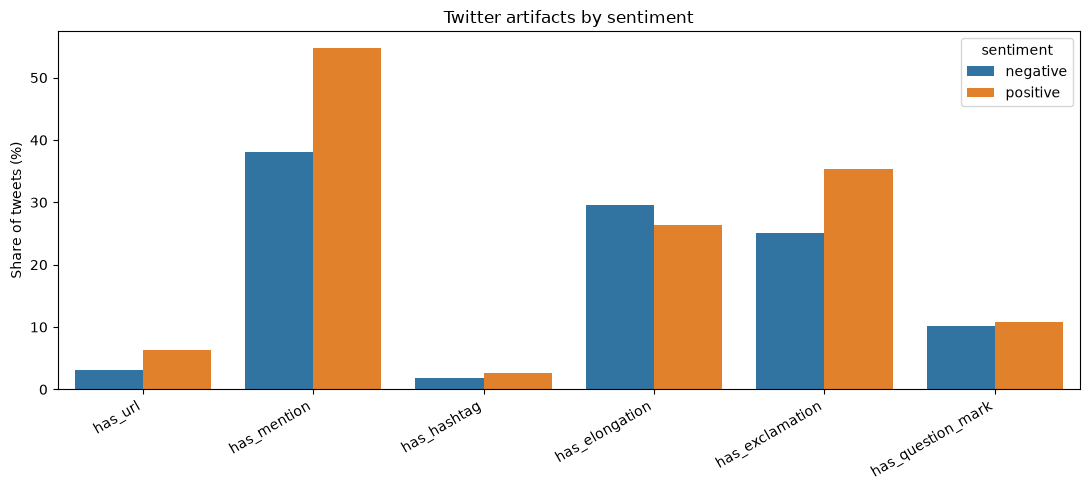

In [155]:
# Reshape the summary table into long format to feed a grouped barplot.
artifact_plot = artifact_summary.reset_index().melt(
    id_vars="sentiment",
    var_name="artifact",
    value_name="share_pct"
)

plt.figure(figsize=(11, 5))
sns.barplot(data=artifact_plot, x="artifact", y="share_pct", hue="sentiment")
plt.xticks(rotation=30, ha="right")
plt.ylabel("Share of tweets (%)")
plt.xlabel("")
plt.title("Twitter artifacts by sentiment")
plt.tight_layout()
plt.show()


This raw-text view matters for the mission because it tells us what should be normalized rather than deleted blindly. For example, links, mentions, hashtags, repeated characters, and strong punctuation may later be replaced by placeholders or normalized forms depending on the model family we use.

### Normalized Lexical Analysis

We now create a lightly normalized version of the tweets for EDA. The objective is not to fully preprocess the data yet, but to separate lexical sentiment patterns from the raw Twitter formatting noise.

#### Utils & Normalization

The normalized EDA text keeps the lexical content while standardizing the main Twitter-specific patterns. This makes the frequency analysis easier to interpret without losing the information that URLs, mentions, and hashtags exist.

In [156]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

custom_stopwords = sorted(set(ENGLISH_STOP_WORDS) - {"no", "not", "nor"})
print("Negation preserved in the custom stopword list:", all(token not in custom_stopwords for token in ["no", "not", "nor"]))

def normalize_for_eda(text):
    """
    Normalize tweet text for exploratory data analysis.

    Steps:
    - convert to string and lowercase
    - unescape HTML entities (e.g "<" or ">")
    - replace URLs with the token " URL "
    - replace user mentions with the token " USER "
    - convert hashtags to " HASHTAG_<tag> "
    - reduce elongated characters to at most two repeats
    - collapse repeated whitespace and strip edges

    Parameters
    ----------
    text : str
        Raw tweet text.

    Returns
    -------
    str
        Normalized tweet suitable for EDA.
    """
    text = html.unescape(str(text).lower())
    text = re.sub(r"http\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = re.sub(r"#(\w+)", r" HASHTAG_\1 ", text)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def matrix_to_count_df(vectorizer, matrix, term_name="term"):
    """
    Aggregate total term counts from a sparse document-term matrix.

    Parameters
    ----------
    vectorizer : CountVectorizer
        Fitted vectorizer that defines the vocabulary.
    matrix : scipy sparse matrix
        Count matrix whose columns correspond to the vectorizer vocabulary.
    term_name : str, default="term"
        Name to use for the vocabulary column in the returned dataframe.

    Returns
    -------
    pandas.DataFrame
        Dataframe containing each term and its total number of appearances.
    """
    return pd.DataFrame({
        term_name: vectorizer.get_feature_names_out(),
        "count": np.asarray(matrix.sum(axis=0)).ravel(),
    }).sort_values("count", ascending=False)

def matrix_to_term_stats_df(vectorizer, matrix, n_docs, term_name="term"):
    """
    Compute tweet-level prevalence statistics for each term.

    Parameters
    ----------
    vectorizer : CountVectorizer
        Fitted vectorizer that defines the vocabulary.
    matrix : scipy sparse matrix
        Count matrix whose rows represent tweets and columns represent terms.
    n_docs : int
        Number of tweets represented by the matrix.
    term_name : str, default="term"
        Name to use for the vocabulary column in the returned dataframe.

    Returns
    -------
    pandas.DataFrame
        Dataframe containing total term counts, number of tweets containing the
        term, and tweet prevalence.
    """
    token_count = np.asarray(matrix.sum(axis=0)).ravel()
    tweet_count = np.asarray((matrix > 0).sum(axis=0)).ravel()
    doc_total = max(int(n_docs), 1)

    return pd.DataFrame({
        term_name: vectorizer.get_feature_names_out(),
        "count": token_count,
        "tweet_count": tweet_count,
        "tweet_prevalence": tweet_count / doc_total,
    }).sort_values("count", ascending=False)

def compare_class_prevalence(pos_stats_df, neg_stats_df, term_name="term"):
    """
    Compare how strongly each term is represented in positive and negative tweets.

    The main comparison metric is tweet prevalence: the share of tweets in a
    sentiment class that contain the term at least once.

    Parameters
    ----------
    pos_stats_df : pandas.DataFrame
        Term statistics computed on positive tweets.
    neg_stats_df : pandas.DataFrame
        Term statistics computed on negative tweets.
    term_name : str, default="term"
        Name of the shared vocabulary column.

    Returns
    -------
    pandas.DataFrame
        Merged dataframe with class-specific statistics and tweet-prevalence
        difference.
    """
    pos_cols = {
        "count": "pos_count",
        "tweet_count": "pos_tweet_count",
        "tweet_prevalence": "pos_tweet_prevalence",
    }
    neg_cols = {
        "count": "neg_count",
        "tweet_count": "neg_tweet_count",
        "tweet_prevalence": "neg_tweet_prevalence",
    }

    compare_df = (
        pos_stats_df.rename(columns=pos_cols)
        .merge(
            neg_stats_df.rename(columns=neg_cols),
            on=term_name,
            how="outer",
        )
        .fillna(0)
    )
    compare_df["prevalence_diff"] = (
        compare_df["pos_tweet_prevalence"] - compare_df["neg_tweet_prevalence"]
    )
    return compare_df.sort_values("prevalence_diff", ascending=False)

data["tweet_eda"] = data["tweet"].apply(normalize_for_eda)
data[["tweet", "tweet_eda"]].sample(5, random_state=RANDOM_STATE)


Negation preserved in the custom stopword list: True


,tweet,tweet_eda
75721,Awwww the AAU days .. I miss them,aww the aau days .. i miss them
80184,Ow... gostei do Destry twitter hein...,ow.. gostei do destry twitter hein..
19864,@Knot2serious Loving a GR8 wkend here in Sedon...,USER loving a gr8 wkend here in sedona! beauti...
76699,Good morning tweetland ! Doing my sunday chore...,good morning tweetland ! doing my sunday chore...
92991,qoodmorninq. on my way to class *killin it po...,qoodmorninq. on my way to class *killin it pon...


#### Most Frequent Terms Without Stopword Filtering

The purpose of this step is to observe the most frequently used words and find if there are words whose presence becomes more salient when considering specific sentiments.

In [157]:
# Build a corpus-wide unigram vocabulary with a minimum support threshold.
unigram_counter = CountVectorizer(min_df=10)
unigram_counter.fit(data["tweet_eda"])

# Create one document-term matrix for the full sample and one for each sentiment class.
all_unigrams_matrix = unigram_counter.transform(data["tweet_eda"])
pos_unigrams_matrix = unigram_counter.transform(data.loc[data["target"] == 1, "tweet_eda"])
neg_unigrams_matrix = unigram_counter.transform(data.loc[data["target"] == 0, "tweet_eda"])

# Summarize raw counts for ranking and descriptive plots.
all_unigrams_df = matrix_to_count_df(unigram_counter, all_unigrams_matrix)
pos_unigrams_df = matrix_to_count_df(unigram_counter, pos_unigrams_matrix)
neg_unigrams_df = matrix_to_count_df(unigram_counter, neg_unigrams_matrix)

# Compute tweet-prevalence statistics before comparing positive and negative corpora.
pos_unigram_stats_df = matrix_to_term_stats_df(
    unigram_counter,
    pos_unigrams_matrix,
    n_docs=(data["target"] == 1).sum(),
)
neg_unigram_stats_df = matrix_to_term_stats_df(
    unigram_counter,
    neg_unigrams_matrix,
    n_docs=(data["target"] == 0).sum(),
)
unigram_compare = compare_class_prevalence(pos_unigram_stats_df, neg_unigram_stats_df)

vocab_size_unfiltered = len(all_unigrams_df)
print(f"Total number of counted words without stopword filtering: {vocab_size_unfiltered}")

all_unigrams_df.head(20)


Total number of counted words without stopword filtering: 6426


,term,count
5972,user,49405
5692,to,35020
5591,the,32615
3752,my,19923
2979,it,19190
321,and,18931
6376,you,18927
2969,is,14772
2208,for,13578
2894,in,13562


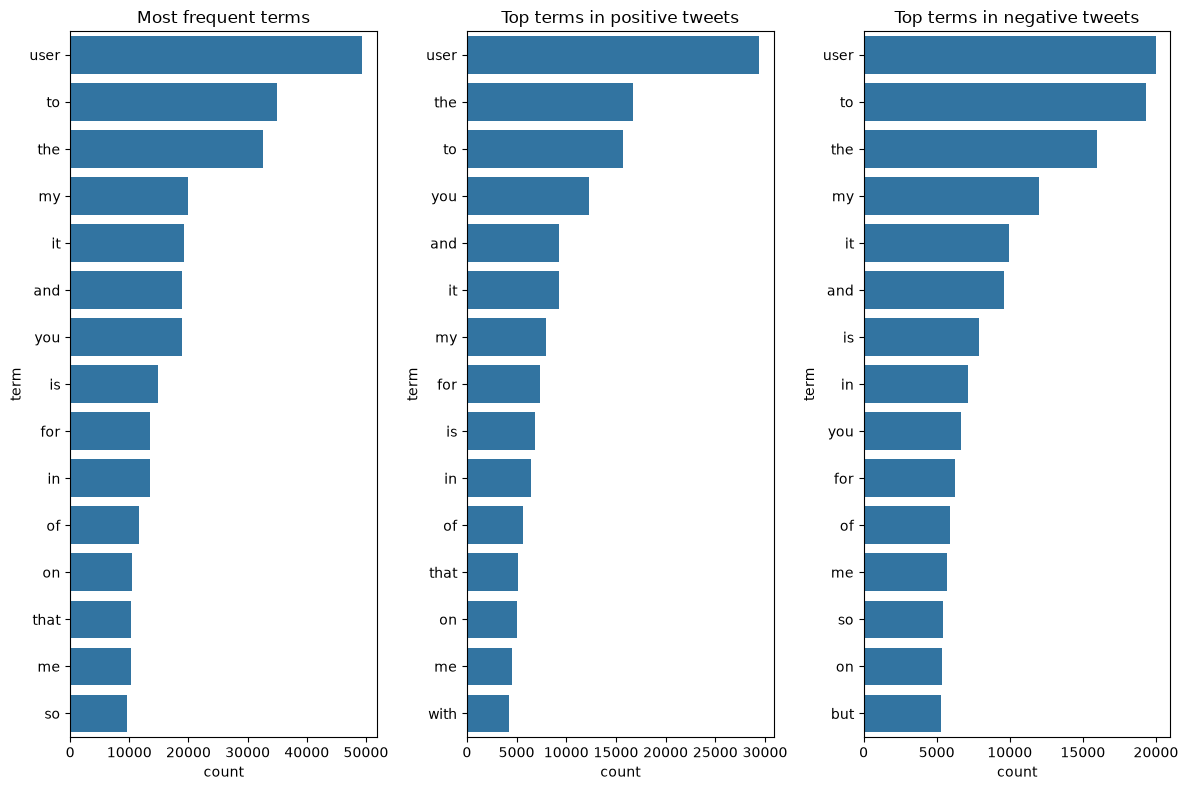

In [158]:
# Compare overall frequency with class-specific frequency rankings.
plt.figure(figsize=(12, 8))
plt.subplot(131)
sns.barplot(data=all_unigrams_df.head(15), y="term", x="count")
plt.title("Most frequent terms")

plt.subplot(132)
sns.barplot(data=pos_unigrams_df.head(15), y="term", x="count")
plt.title("Top terms in positive tweets")

plt.subplot(133)
sns.barplot(data=neg_unigrams_df.head(15), y="term", x="count")
plt.title("Top terms in negative tweets")

plt.tight_layout()
plt.show()


Without stopword filtering, the top rankings are still useful because they show what dominates the corpus globally. In practice, however, these lists often remain saturated with very common function words and generic placeholders, which limits how much they can tell us about sentiment-specific vocabulary. That lead us to further our analysis in the next section.

#### Most Frequent Terms With a Custom Stopword Filter

We now remove frequent English stopwords while preserving negation words such as `no`, `not`, and `nor`.

In [159]:
# Rebuild the vocabulary after removing frequent stopwords while preserving negation.
filtered_unigram_counter = CountVectorizer(min_df=10, stop_words=custom_stopwords)
filtered_unigram_counter.fit(data["tweet_eda"])

# Create document-term matrices on the filtered lexical space.
filtered_all_unigrams_matrix = filtered_unigram_counter.transform(data["tweet_eda"])
filtered_pos_unigrams_matrix = filtered_unigram_counter.transform(data.loc[data["target"] == 1, "tweet_eda"])
filtered_neg_unigrams_matrix = filtered_unigram_counter.transform(data.loc[data["target"] == 0, "tweet_eda"])

# Build descriptive count tables and prevalence tables on the filtered corpus.
filtered_all_unigrams_df = matrix_to_count_df(filtered_unigram_counter, filtered_all_unigrams_matrix)
filtered_pos_unigrams_df = matrix_to_count_df(filtered_unigram_counter, filtered_pos_unigrams_matrix)
filtered_neg_unigrams_df = matrix_to_count_df(filtered_unigram_counter, filtered_neg_unigrams_matrix)
filtered_pos_unigram_stats_df = matrix_to_term_stats_df(
    filtered_unigram_counter,
    filtered_pos_unigrams_matrix,
    n_docs=(data["target"] == 1).sum(),
)
filtered_neg_unigram_stats_df = matrix_to_term_stats_df(
    filtered_unigram_counter,
    filtered_neg_unigrams_matrix,
    n_docs=(data["target"] == 0).sum(),
)
filtered_unigram_compare = compare_class_prevalence(
    filtered_pos_unigram_stats_df,
    filtered_neg_unigram_stats_df,
)

vocab_size_filtered = len(filtered_all_unigrams_df)
print(f"Total number of counted words with custom stopword filtering: {vocab_size_filtered}")

filtered_all_unigrams_df.head(20)


Total number of counted words with custom stopword filtering: 6156


,term,count
5732,user,49405
2975,just,7949
3735,not,6726
2318,good,5895
1450,day,5495
3188,like,4893
5724,url,4839
3716,no,4700
5466,today,4282
6012,work,4176


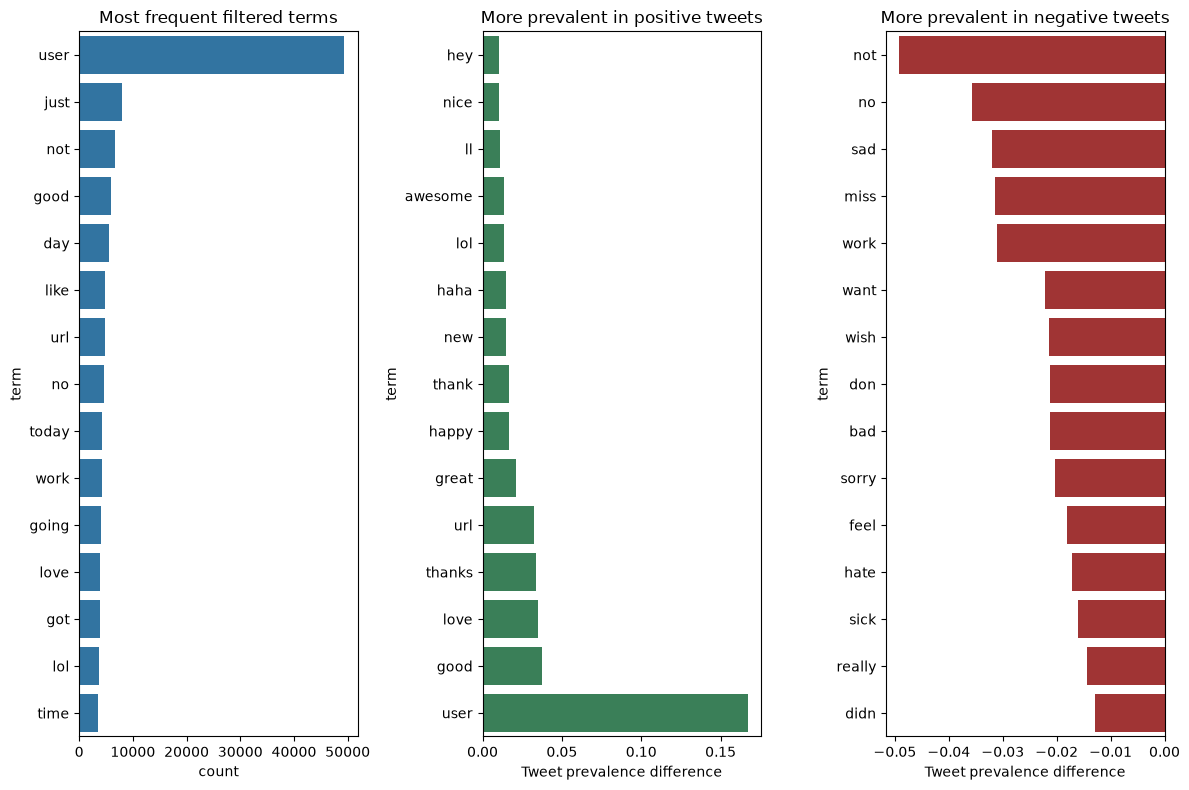

In [160]:
# Select the strongest absolute prevalence gaps in both sentiment directions.
top_positive_terms = (
    filtered_unigram_compare.sort_values("prevalence_diff", ascending=False)
    .head(15)
    .sort_values("prevalence_diff")
)
top_negative_terms = (
    filtered_unigram_compare.sort_values("prevalence_diff", ascending=True)
    .head(15)
)

plt.figure(figsize=(12, 8))
plt.subplot(131)
sns.barplot(data=filtered_all_unigrams_df.head(15), y="term", x="count")
plt.title("Most frequent filtered terms")

plt.subplot(132)
sns.barplot(data=top_positive_terms, y="term", x="prevalence_diff", color="seagreen")
plt.title("More prevalent in positive tweets")
plt.xlabel("Tweet prevalence difference")

plt.subplot(133)
sns.barplot(data=top_negative_terms, y="term", x="prevalence_diff", color="firebrick")
plt.title("More prevalent in negative tweets")
plt.xlabel("Tweet prevalence difference")

plt.tight_layout()
plt.show()


The prevalence-difference ranking above is useful, but it does not tell us whether a gap is large relative to the base prevalence of the term itself. So we can't know how relevant is the prevalence difference for each term. We therefore build a normalized indicator, the **relative tweet prevalence difference**, defined as the prevalence gap divided by the strongest class prevalence of the term.


In [161]:
# Normalize each prevalence gap by the stronger class prevalence of the term itself.
filtered_unigram_compare["relative_prevalence_diff"] = (
    filtered_unigram_compare["prevalence_diff"]
    / np.maximum(
        filtered_unigram_compare["pos_tweet_prevalence"].abs(),
        filtered_unigram_compare["neg_tweet_prevalence"].abs(),
    )
)

filtered_unigram_compare.sort_values(
    "relative_prevalence_diff",
    ascending=False
).head(20)


,term,pos_count,pos_tweet_count,pos_tweet_prevalence,neg_count,neg_tweet_count,neg_tweet_prevalence,prevalence_diff,relative_prevalence_diff
2591,hihi,14,14,0.00028,0,0,0.00000,0.00028,1.000000
2553,heehee,14,14,0.00028,0,0,0.00000,0.00028,1.000000
4532,romantic,15,14,0.00028,0,0,0.00000,0.00028,1.000000
3113,laughter,14,13,0.00026,0,0,0.00000,0.00026,1.000000
705,boa,10,10,0.00020,0,0,0.00000,0.00020,1.000000
4330,rb,17,16,0.00032,0,0,0.00000,0.00032,1.000000
4100,poem,12,12,0.00024,0,0,0.00000,0.00024,1.000000
464,awesomee,12,12,0.00024,0,0,0.00000,0.00024,1.000000
3691,nicee,12,12,0.00024,0,0,0.00000,0.00024,1.000000
1527,designs,12,12,0.00024,0,0,0.00000,0.00024,1.000000


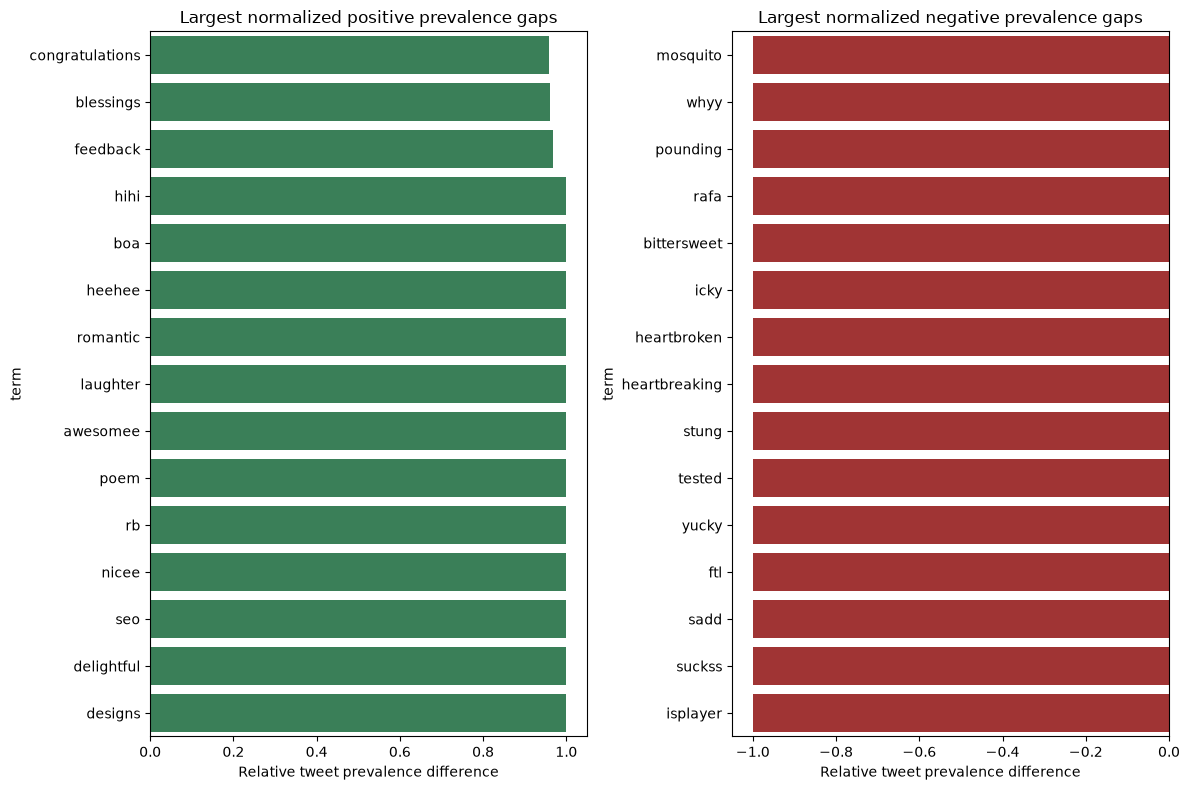

In [162]:
top_positive_terms_relative = (
    filtered_unigram_compare.sort_values("relative_prevalence_diff", ascending=False)
    .head(15)
    .sort_values("relative_prevalence_diff")
)
top_negative_terms_relative = (
    filtered_unigram_compare.sort_values("relative_prevalence_diff", ascending=True)
    .head(15)
)

plt.figure(figsize=(12, 8))
plt.subplot(121)
sns.barplot(
    data=top_positive_terms_relative,
    y="term",
    x="relative_prevalence_diff",
    color="seagreen",
)
plt.title("Largest normalized positive prevalence gaps")
plt.xlabel("Relative tweet prevalence difference")

plt.subplot(122)
sns.barplot(
    data=top_negative_terms_relative,
    y="term",
    x="relative_prevalence_diff",
    color="firebrick",
)
plt.title("Largest normalized negative prevalence gaps")
plt.xlabel("Relative tweet prevalence difference")

plt.tight_layout()
plt.show()


The normalized ranking above shows us words that appear totally, or with a massive majority, only on a specific sentiment class. It is useful but it can still overvalue rare terms. To focus on words supported by a broader base of tweets, we now require a minimum number of tweets containing the term across both sentiment classes before recomputing the relative tweet prevalence difference ranking. Doing that, we can observe the behavior of more frequenly used words.


In [163]:
# Keep only terms supported by at least a minimum number of tweets across both classes.
MIN_SUPPORT_TWEETS = 100

supported_filtered_unigram_compare = filtered_unigram_compare[
    (filtered_unigram_compare["pos_tweet_count"] + filtered_unigram_compare["neg_tweet_count"]) >= MIN_SUPPORT_TWEETS
].copy()

print(
    f"Number of terms kept with a minimum support of {MIN_SUPPORT_TWEETS} tweets: "
    f"{len(supported_filtered_unigram_compare):,}"
)

supported_filtered_unigram_compare.sort_values(
    "relative_prevalence_diff",
    ascending=False
).head(20)


Number of terms kept with a minimum support of 100 tweets: 926


,term,pos_count,pos_tweet_count,pos_tweet_prevalence,neg_count,neg_tweet_count,neg_tweet_prevalence,prevalence_diff,relative_prevalence_diff
2491,hashtag_followfriday,154,153,0.00306,11,11,0.00022,0.00284,0.928105
5903,welcome,416,414,0.00828,33,33,0.00066,0.00762,0.920290
5375,thank,970,946,0.01892,126,124,0.00248,0.01644,0.868922
4896,smile,183,174,0.00348,25,25,0.00050,0.00298,0.856322
4246,proud,130,129,0.00258,19,19,0.00038,0.00220,0.852713
1232,congrats,186,186,0.00372,30,30,0.00060,0.00312,0.838710
5379,thanks,2072,2049,0.04098,362,361,0.00722,0.03376,0.823816
5428,thx,140,139,0.00278,29,26,0.00052,0.00226,0.812950
3566,mothers,113,98,0.00196,23,22,0.00044,0.00152,0.775510
1824,enjoyed,85,84,0.00168,19,19,0.00038,0.00130,0.773810


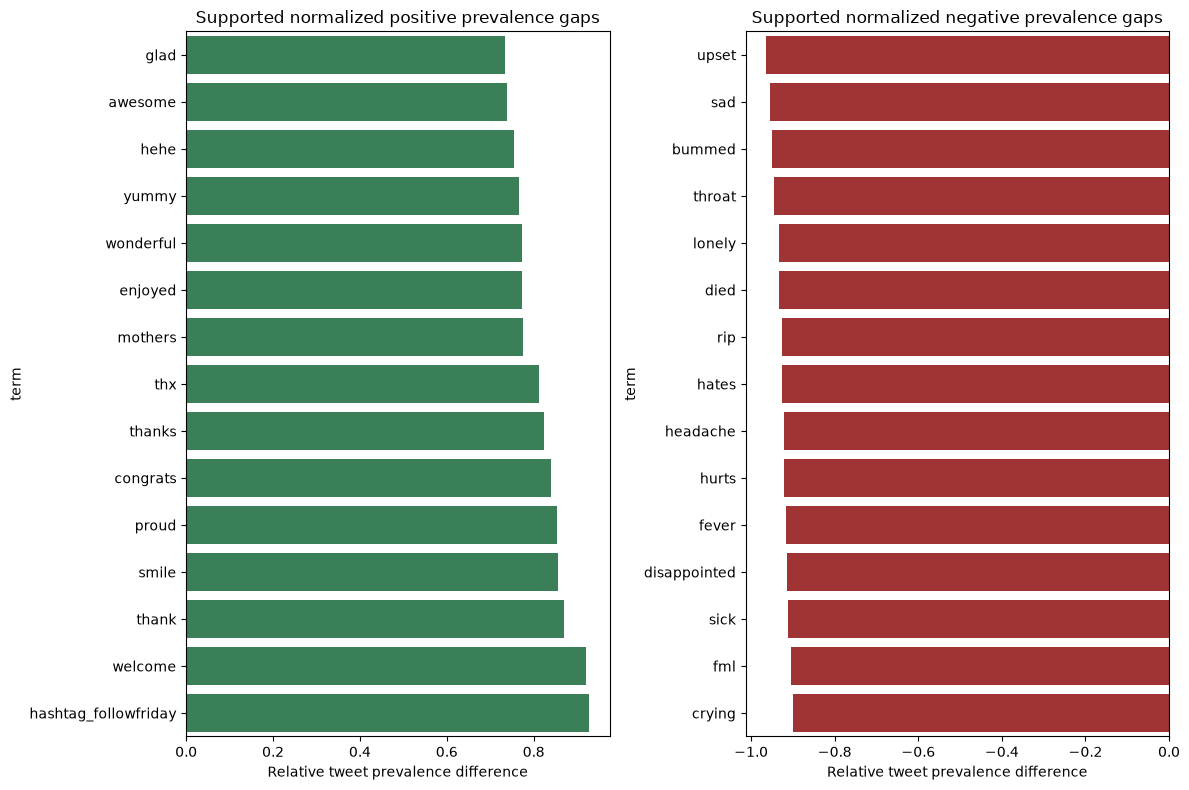

In [164]:
top_positive_terms_relative_supported = (
    supported_filtered_unigram_compare.sort_values("relative_prevalence_diff", ascending=False)
    .head(15)
    .sort_values("relative_prevalence_diff")
)
top_negative_terms_relative_supported = (
    supported_filtered_unigram_compare.sort_values("relative_prevalence_diff", ascending=True)
    .head(15)
)

plt.figure(figsize=(12, 8))
plt.subplot(121)
sns.barplot(
    data=top_positive_terms_relative_supported,
    y="term",
    x="relative_prevalence_diff",
    color="seagreen",
)
plt.title("Supported normalized positive prevalence gaps")
plt.xlabel("Relative tweet prevalence difference")

plt.subplot(122)
sns.barplot(
    data=top_negative_terms_relative_supported,
    y="term",
    x="relative_prevalence_diff",
    color="firebrick",
)
plt.title("Supported normalized negative prevalence gaps")
plt.xlabel("Relative tweet prevalence difference")

plt.tight_layout()
plt.show()


This analysis supports the intuition that sentiment-oriented words are more prevalent in tweets of the corresponding sentiment class. The key questions now become more operational: how large are these prevalence gaps, and are they strong enough to influence our preprocessing or modeling choices?

We still cannot answer those questions definitively from EDA alone, but we can already retain three practical takeaways:
- we are entering the benchmarking and modeling phase with a clearer lexical understanding of the dataset,
- word-based modeling approaches remain worth testing even if EDA cannot yet predict their final performance,
- for some models, stopword filtering is a reasonable preprocessing experiment to include in the benchmark.

The current prevalence-based indicators also suggest that negative-oriented words may be more class-specific than positive-oriented words. Put differently, negative-oriented words seem to appear less often in positive tweets than positive-oriented words appear in negative tweets.

**Question:** could that make negative tweets easier to classify?

We will keep this hypothesis in mind and test it during the modeling phase.


#### Frequent Expressions (Bigrams and Trigrams)

Expressions are particularly useful for sentiment analysis because polarity is often carried by short phrases rather than isolated words.

In [165]:
# Build a bigram/trigram vocabulary on the normalized, stopword-filtered tweets.
ngram_counter = CountVectorizer(ngram_range=(2, 3), min_df=10, stop_words=custom_stopwords)
ngram_counter.fit(data["tweet_eda"])

# Create expression-level document-term matrices for the full sample and each class.
all_ngrams_matrix = ngram_counter.transform(data["tweet_eda"])
pos_ngrams_matrix = ngram_counter.transform(data.loc[data["target"] == 1, "tweet_eda"])
neg_ngrams_matrix = ngram_counter.transform(data.loc[data["target"] == 0, "tweet_eda"])

# Build descriptive count tables and prevalence tables for expressions.
all_ngrams_df = matrix_to_count_df(ngram_counter, all_ngrams_matrix, term_name="expression")
pos_ngrams_df = matrix_to_count_df(ngram_counter, pos_ngrams_matrix, term_name="expression")
neg_ngrams_df = matrix_to_count_df(ngram_counter, neg_ngrams_matrix, term_name="expression")
pos_ngram_stats_df = matrix_to_term_stats_df(
    ngram_counter,
    pos_ngrams_matrix,
    n_docs=(data["target"] == 1).sum(),
    term_name="expression",
)
neg_ngram_stats_df = matrix_to_term_stats_df(
    ngram_counter,
    neg_ngrams_matrix,
    n_docs=(data["target"] == 0).sum(),
    term_name="expression",
)
ngram_compare = compare_class_prevalence(
    pos_ngram_stats_df,
    neg_ngram_stats_df,
    term_name="expression",
)

expression_vocab_size = len(all_ngrams_df)
print(f"Total number of counted expressions: {expression_vocab_size}")

all_ngrams_df.head(20)


Total number of counted expressions: 4151


,expression,count
3723,user user,1940
3663,user thanks,1114
3524,user oh,962
3431,user lol,825
3504,user no,820
3277,user good,772
3340,user hey,765
3800,user yeah,762
1311,just got,713
804,good morning,705


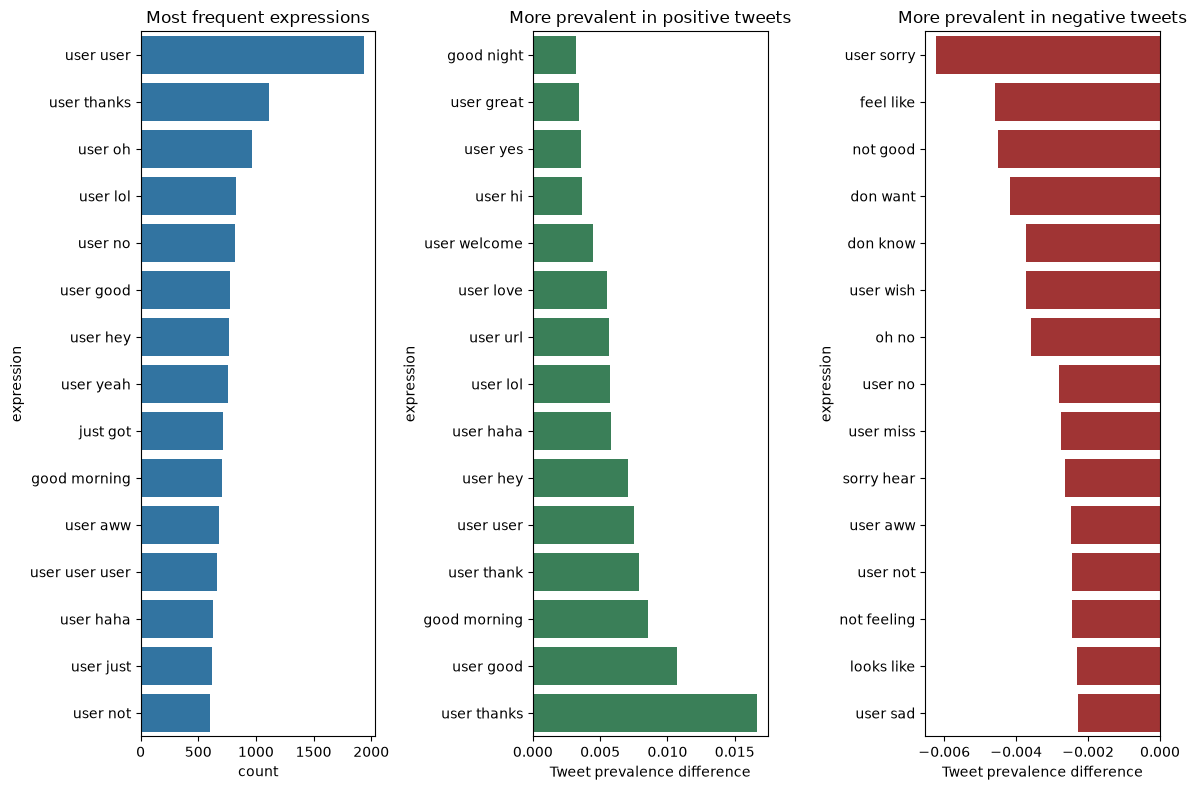

In [171]:
# Rank expressions by absolute prevalence gap before looking at normalized scores.
top_positive_expressions = (
    ngram_compare.sort_values("prevalence_diff", ascending=False)
    .head(15)
    .sort_values("prevalence_diff")
)
top_negative_expressions = (
    ngram_compare.sort_values("prevalence_diff", ascending=True)
    .head(15)
)

plt.figure(figsize=(12, 8))
plt.subplot(131)
sns.barplot(data=all_ngrams_df.head(15), y="expression", x="count")
plt.title("Most frequent expressions")

plt.subplot(132)
sns.barplot(data=top_positive_expressions, y="expression", x="prevalence_diff", color="seagreen")
plt.title("More prevalent in positive tweets")
plt.xlabel("Tweet prevalence difference")

plt.subplot(133)
sns.barplot(data=top_negative_expressions, y="expression", x="prevalence_diff", color="firebrick")
plt.title("More prevalent in negative tweets")
plt.xlabel("Tweet prevalence difference")

plt.tight_layout()
plt.show()


As with individual words, the absolute prevalence gap is only a first layer of interpretation. We therefore normalize each expression gap by the stronger class prevalence of the expression itself.


In [167]:
# Normalize each expression gap by the stronger class prevalence of the expression.
ngram_compare["relative_prevalence_diff"] = (
    ngram_compare["prevalence_diff"]
    / np.maximum(
        ngram_compare["pos_tweet_prevalence"].abs(),
        ngram_compare["neg_tweet_prevalence"].abs(),
    )
)

ngram_compare.sort_values(
    "relative_prevalence_diff",
    ascending=False
).head(20)


,expression,pos_count,pos_tweet_count,pos_tweet_prevalence,neg_count,neg_tweet_count,neg_tweet_prevalence,prevalence_diff,relative_prevalence_diff
7,100 followers,85,85,0.00170,0,0,0.0,0.00170,1.0
3271,user glad like,11,11,0.00022,0,0,0.0,0.00022,1.0
3062,url add,82,82,0.00164,0,0,0.0,0.00164,1.0
3935,watching hannah montana,11,11,0.00022,0,0,0.0,0.00022,1.0
1154,hope wonderful,11,11,0.00022,0,0,0.0,0.00022,1.0
563,feel special,11,11,0.00022,0,0,0.0,0.00022,1.0
248,come join,11,11,0.00022,0,0,0.0,0.00022,1.0
3461,user love new,16,16,0.00032,0,0,0.0,0.00032,1.0
3317,user happy mother,11,11,0.00022,0,0,0.0,0.00022,1.0
2666,stay tuned,11,11,0.00022,0,0,0.0,0.00022,1.0


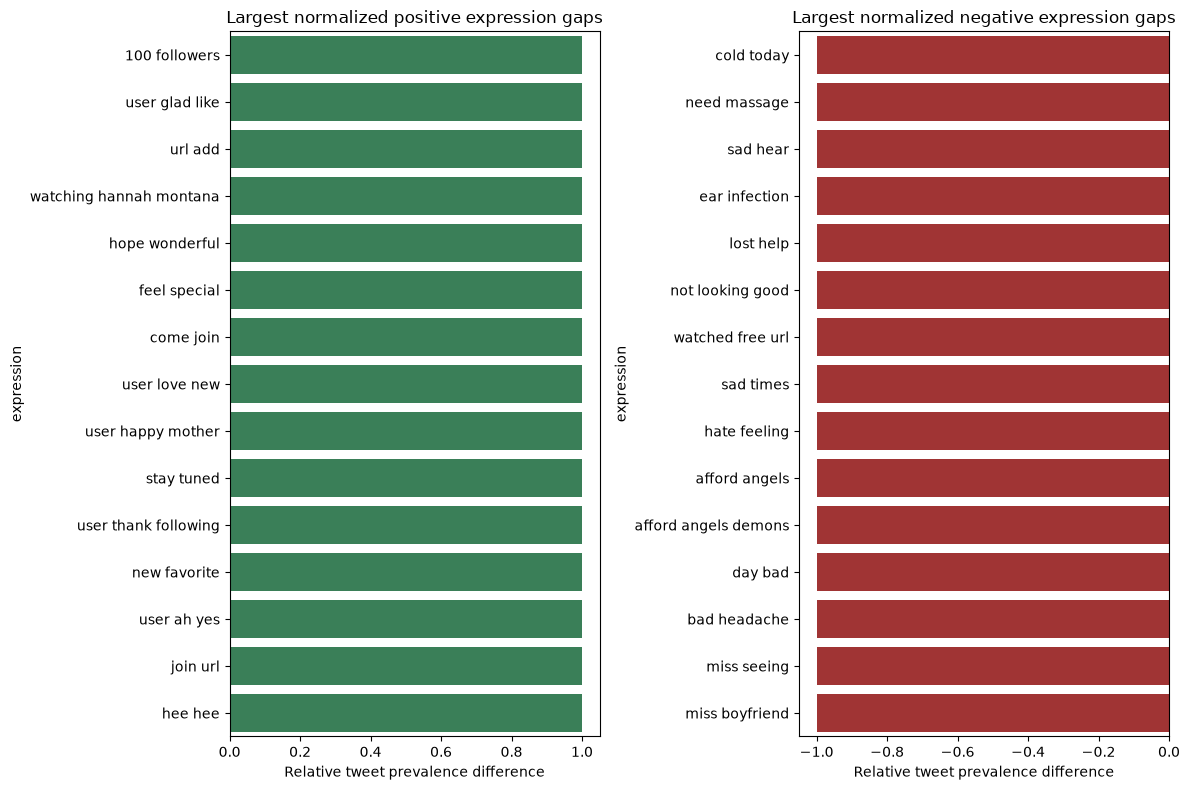

In [168]:
# Visualize the strongest normalized expression gaps in each sentiment direction.
top_positive_expressions_relative = (
    ngram_compare.sort_values("relative_prevalence_diff", ascending=False)
    .head(15)
    .sort_values("relative_prevalence_diff")
)
top_negative_expressions_relative = (
    ngram_compare.sort_values("relative_prevalence_diff", ascending=True)
    .head(15)
)

plt.figure(figsize=(12, 8))
plt.subplot(121)
sns.barplot(
    data=top_positive_expressions_relative,
    y="expression",
    x="relative_prevalence_diff",
    color="seagreen",
)
plt.title("Largest normalized positive expression gaps")
plt.xlabel("Relative tweet prevalence difference")

plt.subplot(122)
sns.barplot(
    data=top_negative_expressions_relative,
    y="expression",
    x="relative_prevalence_diff",
    color="firebrick",
)
plt.title("Largest normalized negative expression gaps")
plt.xlabel("Relative tweet prevalence difference")

plt.tight_layout()
plt.show()


As with words, normalized prevalence gaps can overemphasize rare expressions. We therefore add the same minimum-support filter before drawing stronger conclusions from the ranking.


In [169]:
# Keep only expressions supported by a minimum number of tweets across both classes.
MIN_SUPPORT_EXPRESSIONS = 100

supported_ngram_compare = ngram_compare[
    (ngram_compare["pos_tweet_count"] + ngram_compare["neg_tweet_count"]) >= MIN_SUPPORT_EXPRESSIONS
].copy()

print(
    f"Number of expressions kept with a minimum support of {MIN_SUPPORT_EXPRESSIONS} tweets: "
    f"{len(supported_ngram_compare):,}"
)

supported_ngram_compare.sort_values(
    "relative_prevalence_diff",
    ascending=False
).head(20)


Number of expressions kept with a minimum support of 100 tweets: 145


,expression,pos_count,pos_tweet_count,pos_tweet_prevalence,neg_count,neg_tweet_count,neg_tweet_prevalence,prevalence_diff,relative_prevalence_diff
3766,user welcome,237,237,0.00474,14,14,0.00028,0.00446,0.940928
3660,user thank,432,432,0.00864,37,37,0.00074,0.00790,0.914352
3315,user happy,169,169,0.00338,19,19,0.00038,0.00300,0.887574
3282,user good morning,139,139,0.00278,18,18,0.00036,0.00242,0.870504
3337,user hello,119,119,0.00238,16,16,0.00032,0.00206,0.865546
3663,user thanks,973,972,0.01944,141,141,0.00282,0.01662,0.854938
3290,user great,202,202,0.00404,30,30,0.00060,0.00344,0.851485
1926,mothers day,94,87,0.00174,14,13,0.00026,0.00148,0.850575
3281,user good luck,104,104,0.00208,17,17,0.00034,0.00174,0.836538
1924,mother day,103,99,0.00198,18,17,0.00034,0.00164,0.828283


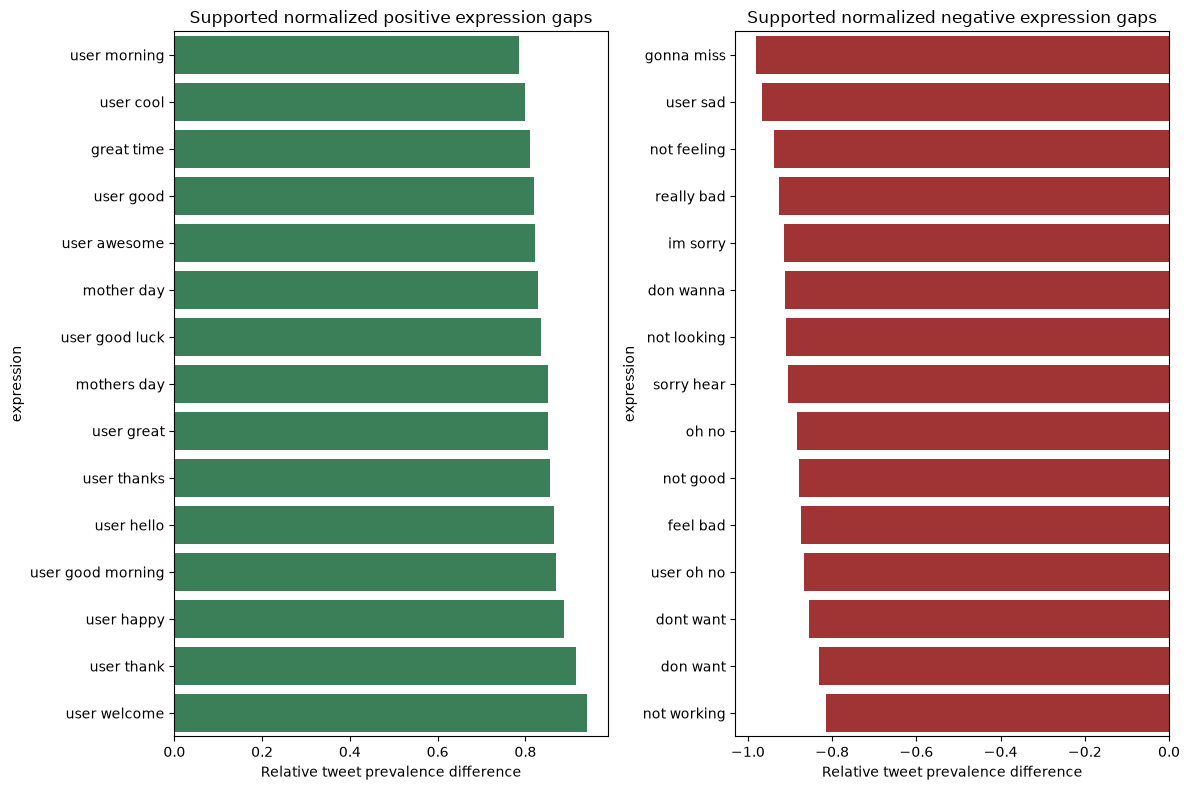

In [170]:
# Visualize the strongest normalized expression gaps after the support filter.
top_positive_expressions_supported = (
    supported_ngram_compare.sort_values("relative_prevalence_diff", ascending=False)
    .head(15)
    .sort_values("relative_prevalence_diff")
)
top_negative_expressions_supported = (
    supported_ngram_compare.sort_values("relative_prevalence_diff", ascending=True)
    .head(15)
)

plt.figure(figsize=(12, 8))
plt.subplot(121)
sns.barplot(
    data=top_positive_expressions_supported,
    y="expression",
    x="relative_prevalence_diff",
    color="seagreen",
)
plt.title("Supported normalized positive expression gaps")
plt.xlabel("Relative tweet prevalence difference")

plt.subplot(122)
sns.barplot(
    data=top_negative_expressions_supported,
    y="expression",
    x="relative_prevalence_diff",
    color="firebrick",
)
plt.title("Supported normalized negative expression gaps")
plt.xlabel("Relative tweet prevalence difference")

plt.tight_layout()
plt.show()


This staged expression analysis complements the unigram section. It lets us check whether sentiment is carried only by isolated words or whether stable short phrases also provide a robust signal, even after we control for prevalence normalization and minimum support.


The expression analysis is especially relevant for the mission because it tells us whether polarity emerges through short lexical patterns and whether placeholders such as `URL` or `USER` remain informative after normalization. If they do, we should normalize them carefully later rather than removing them blindly.

### Tweets' Timeline

We finally inspect the time dimension of the corpus to detect any temporal irregularities that could affect splitting strategy or bias the interpretation of the data.

In [172]:
def date_converter(date_time_string, format="%a %b %d %H:%M:%S %Y"):
    """Convert a Sentiment140 datetime string to a Python date."""
    date_time = date_time_string.replace("PDT ", "")
    return datetime.strptime(date_time, format).date()

data["date"] = data["datetime"].apply(date_converter)
data_daily = data.groupby("date").agg(
    nb_tweets=("tweet", "count"),
    nb_tweets_pos=("target", "sum"),
)
data_daily["rate_tweets_pos"] = 100 * data_daily["nb_tweets_pos"] / data_daily["nb_tweets"]
data_daily.head()


,nb_tweets,nb_tweets_pos,rate_tweets_pos
date,,,
2009-04-06,211,119,56.398104
2009-04-07,1071,642,59.943978
2009-04-17,204,125,61.274510
2009-04-18,1302,731,56.144393
2009-04-19,1708,1011,59.192037


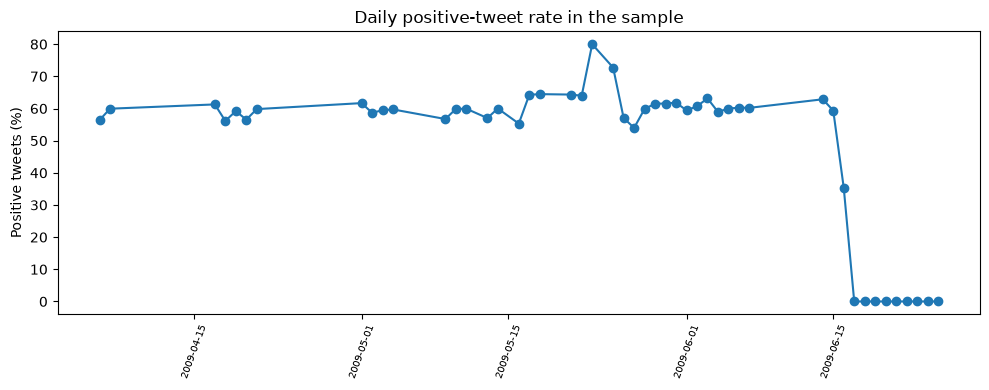

In [173]:
plt.figure(figsize=(10, 4))
plt.plot(data_daily.index, data_daily["rate_tweets_pos"], marker="o")
plt.xticks(rotation=70, fontsize=7)
plt.title("Daily positive-tweet rate in the sample")
plt.ylabel("Positive tweets (%)")
plt.tight_layout()
plt.show()


The sample timeline may reveal unusual behavior, but we still need to verify whether that behavior comes from sampling or from the original dataset itself.

In [174]:
tweets["date"] = tweets["datetime"].apply(date_converter)
tweets_daily = tweets.groupby("date").agg(
    nb_tweets=("tweet", "count"),
    nb_tweets_pos=("target", "sum"),
)
tweets_daily["rate_tweets_pos"] = 100 * tweets_daily["nb_tweets_pos"] / tweets_daily["nb_tweets"]
tweets_daily.head()


,nb_tweets,nb_tweets_pos,rate_tweets_pos
date,,,
2009-04-06,3360,1934,57.559524
2009-04-07,17311,10162,58.702559
2009-04-17,3084,1840,59.662776
2009-04-18,21754,12714,58.444424
2009-04-19,27469,16042,58.400379


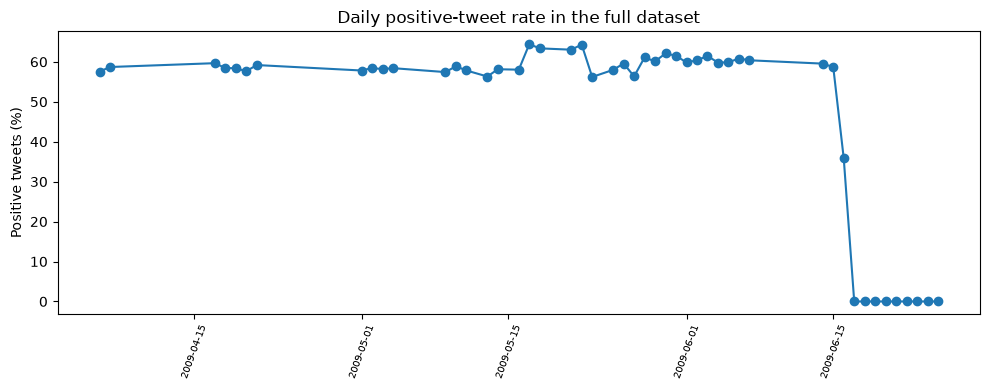

In [175]:
plt.figure(figsize=(10, 4))
plt.plot(tweets_daily.index, tweets_daily["rate_tweets_pos"], marker="o")
plt.xticks(rotation=70, fontsize=7)
plt.title("Daily positive-tweet rate in the full dataset")
plt.ylabel("Positive tweets (%)")
plt.tight_layout()
plt.show()


The drop to a fully negative tail is a property of the original dataset, not a sampling artifact. For the mission, this means we should be careful with chronological splits: a random stratified split is appropriate as our mission is to predict negative tweets and anticipate bad buzz using only the tweets' content.

### EDA Synthesis for the Mission

- The raw import must preserve all characters, because Twitter-specific artifacts can later guide preprocessing and sentiment extraction.
- The label mapping is documented by the dataset itself: `0` means negative and `4` means positive, which we remap to `1` for binary classification.
- Tweet-length percentiles will help us choose reasonable sequence lengths for the neural architectures.
- URLs, mentions, hashtags, repeated characters, and strong punctuation are common enough to deserve explicit preprocessing rules.
- Frequency analysis is more informative after light normalization and a custom stopword filter that preserves negation.
- The lexical analysis show that there are terms and expressions whose relative frequency becomes more prominent in one sentiment class.
- The timeline analysis reveals a temporal irregularity in the source data, which is important when we later define train/validation/test splitting strategies.

## Modelisation

The objective of the project is to predict the sentiment associated with a tweet. As explained above, the process will be split into three steps that will form a pipeline we will apply to the data independantly of the models used. These steps are :

- Pre Processing : each model has its format in which it accepts inputs and also has some specific cleaning processes to optimize performances

- Embedding : vectorize the tweets and extract relevant features for the next step's classifying model. We will work with three embedding models : tf-idf, fasttext or Glove, BERT.

- Classifying : training a model to predict the sentiment associated to a tweet's embedding. We will also work with 3 different models : Logistic Regression, DL model (LSTM, GRU, CNN), BERT

In [ ]:
mlflow.set_tracking_uri(f"sqlite:///{GLOBAL_PATH}mlflow.db")
# mlflow.create_experiment(
#     name ="OC Project 7-test",
#     artifact_location=f"{GLOBAL_PATH}artifacts"
# ) 
experiment = mlflow.set_experiment("OC Project 7")


## General Pre Processing

With this step, we introduce the general pre processing methods on the whole data for it to contain somewhat processable words and expressions for whatever embedding model that may come after. After that, we will introduce and apply the additional processing proper to each model.

In [ ]:
# let's see some examples of the raw tweets
for tweet in data['tweet'].sample(10):
    print(tweet)

Running the above cell a few times helps see the words or expressions that may be difficult to process for embedding models (as we mentioned in the introduction above) : user mentions, word elongations/repetions, html caracter representations (e.g. \"&amp;" for &amp;), ascii emoticons, links, hashtags, etc. There is also the case of numbers who may have have contextual signification but don't have meaning when taken separately which will be the case for many embedding models. Those are in the most cases expressions that are not handled by embedding models so we introduce the next functions to replace those expressions by corresponding more appropriate expressions.

In [ ]:
def clean_links(tweet, replace_links=False):
    '''return a tweet cleaned from all the 'http', 'https' and 'www' types of links. If 'replace_links' is True,
    links are replaced by the expression <link>. Else they are just cleaned.'''
    format_links = "(?:https?://\S+|www\.\S+)"
    replacement = ''
    if replace_links:
        replacement = "<link>"
    tweet = re.sub(format_links, replacement, tweet)
    return tweet

def clean_mentions(tweet, replace_mentions=False):
    '''return a tweet cleaned from all '@' mentions replaced by a <user> expression. If 'replace_mentions' is True,
    mentions are replaced by the expression <user>. Else they are just cleaned.'''
    format_mentions = "@\w+"
    replacement = ''
    if replace_mentions:
        replacement = "<user>"
    tweet = re.sub(format_mentions, replacement, tweet)
    return tweet

def clean_hashtags(tweet, replace_hashtags=False):
    '''return a tweet cleaned from hashtags. If 'replace_hashtags' is True,
    hashtags are replaced by the expression <hashtag> + the hashtag word in all capitals. Else they are just cleaned.

    Example : #happy becomes <hashtag> HAPPY if 'replace_hashtags' is True.'''

    format_hashtags = r"#(\w+)"

    if replace_hashtags:
        tweet = re.sub(
            format_hashtags,
            lambda m: "<hashtag> " + m.group(1).upper(),
            tweet
        )
    else:
        tweet = re.sub(format_hashtags, "", tweet)

    return tweet

def clean_emojis(tweet, replace_ascii_emojis=False):
    '''return a tweet cleaned from ASCII emojis. If 'replace_ascii_emojis' is True,
    ascii formated emojis are replaced by the expression < 'emotion related to the emoji' >. Else they are just cleaned.

    Example : :-) becomes <smile>'''
    eyes = r"[8:=;]"
    nose = r"['\-]?"
    if replace_ascii_emojis:
        tweet = re.sub(r"{}{}[)dD]+|[)dD]+{}{}".format(eyes, nose, nose, eyes), "<smile>", tweet)
        tweet = re.sub(r"{}{}p+".format(eyes, nose), "<lolface>", tweet)
        tweet = re.sub(r"{}{}\(+|\)+{}{}".format(eyes, nose, nose, eyes), "<sadface>", tweet)
        tweet = re.sub(r"{}{}[\/|l*]".format(eyes, nose), "<neutralface>", tweet)
        tweet = re.sub(r"<3","<heart>", tweet)
    else:
        tweet = re.sub(r"{}{}[)dD]+|[)dD]+{}{}".format(eyes, nose, nose, eyes), "", tweet)
        tweet = re.sub(r"{}{}p+".format(eyes, nose), "", tweet)
        tweet = re.sub(r"{}{}\(+|\)+{}{}".format(eyes, nose, nose, eyes), "", tweet)
        tweet = re.sub(r"{}{}[\/|l*]".format(eyes, nose), "", tweet)
        tweet = re.sub(r"<3","", tweet)

    return tweet

def clean_emails(tweet, replace_emails=False):
    '''return a tweet cleaned from email type adresses. If 'replace_emails' is True,
    emails are replaced by the expression <email>. Else they are just cleaned.'''
    email_pattern = "\b[\w\.-]+@[\w\.-]+\.\w+\b"
    replacement = ''
    if replace_emails:
        replacement="<email>"

    return re.sub(email_pattern, replacement, tweet)

def clean_elongation(tweet):
    "return a tweet where elongated characters are reduced to 2 for letters and to 1 for punctuations."
    tweet = re.sub(r"([A-Za-z])\1{2,}", r"\1\1", tweet)
    tweet = re.sub(r"([!?.,])\1{1,}", r"\1", tweet)

    return tweet

def clean_numbers(tweet):
    '''return a tweet cleaned from numbers which are replaced.

    Example : 100 $ --> \<number> $'''
    tweet = re.sub(r"[-+]?[.\d]*[\d]+[:,.\d]*", "<number>", tweet)
    return tweet


def clean_tweet(tweet, replace_numbers=False, replace_links=False, replace_mentions=False, replace_hashtags=False, replace_ascii_emojis=False, replace_emails=False):
    '''returns a cleaned tweet where the numbers, links, emails, hastags, emoticons, and elongated words got deleted or replaced by
    corresponding expressions. The boolean parameters describe whether or not the mentioned kind of expressions should be replaced or just
    cleaned. It also replxaces html representations of characters by their original characters and replaces unicode emojis.

    Examples :
            😆 --> \<grinning_squinting_face\>;
            \&quot; --> ' " ';
            www.website.com --> \<link>;
            adresse@gmail.com --> \<email>;
            #happy --> \<hashtag\> HAPPY;
            @some_friend --> \<user>;
            :-) --> \<smile>;
            greaaaaat --> greaat
            100 $ --> \<number> $
            '''
    tweet_clean = clean_links(tweet, replace_links)
    tweet_clean = clean_emails(tweet_clean, replace_emails)
    tweet_clean = clean_hashtags(tweet_clean, replace_hashtags)
    tweet_clean = clean_mentions(tweet_clean, replace_mentions)
    tweet_clean = clean_emojis(tweet_clean, replace_ascii_emojis)
    tweet_clean = clean_elongation(tweet_clean)
    tweet_clean = html.unescape(emoji.demojize(tweet_clean))
    if replace_numbers:
        tweet_clean = clean_numbers(tweet_clean)

    return tweet_clean

Let's see the effect of our cleaning on some tweet examples.

In [ ]:
# defining the cleaning hyperparameters
# we will use this setup for most of the embedding methods we will use
cleaning_params = {
    "replace_links" : False, # just clean all links
    "replace_mentions" : True,
    "replace_hashtags" : True,
    "replace_ascii_emojis" : True,
    "replace_emails" : False, # clean all emails
    "replace_numbers" : True
}

In [ ]:
for tweet in data['tweet'].sample(5):
    print("Original Tweet : ", tweet)
    print("Cleaned Tweet : ", clean_tweet(tweet, **cleaning_params))

## Train / Validation / Test : Dataset Creation

In [ ]:
data_train, data_test = train_test_split(data, train_size=0.75, stratify=data['target'])

In [ ]:
data_train.value_counts('target')

In [ ]:
data_test.value_counts('target')

In [ ]:
data_train['tweet_clean'] = data_train['tweet'].apply(clean_tweet, **cleaning_params)
data_train.head()

In [ ]:
data_test['tweet_clean'] = data_test['tweet'].apply(clean_tweet, **cleaning_params)
data_test.head()

## Performance Metrics

We are going to train and test different pipelines of models for our Sentiment Analysis task, with different combinations of hyperparameters for each, so we need some measurement system we will use to compare the performances of all these models. We can use different metrics depending of which part of the **whole** process we are trying to evaluate :
* **loss function** : a constant of machine learning training algorithms. It generally is a mathematical function very sensible to parameter changes and is used to direct the optimization of the parameters of a model during learning. This metric can strongly depend on the hyperparameters so it is better used for describing the behavior of the model during training and also between training and testing.
* **Accuracy, Recall, Fbeta Scores** : these metrics offer a more concrete insight on the predictions that the model is doing as they describe its successes and failures. The Engineer can use them to choose which model or which combination of hyperparameters will behave the best in production environment when facing new data.
* **A Customized Metric** : we can also create some metrics to describe different or more intuitive stories from the training of our models. In this case of Sentiment Analysis where we want to predict **bad buzzes**, we can say that it is more important for our model to not mispredict **Negative tweets** into **Positive Tweets**. We can then try to measure the number of Truly Negative tweets that are mispredicted for (let's say) a group of 1000 tweets.

In [ ]:
# definition of the customized metrics
def badbuzz_miss_rate(y_true, y_pred):
    """computes the probable number of mispredicted Negative Tweets by using the confusion matrix of a model's predictions"""
    c = confusion_matrix(y_true, y_pred)
    false_positive_rate = round(1000 * c[0][1]/(c[0][0]+c[0][1])) # number of negative tweets predicted
                                                                 # as positive by the total number of negative tweets

    return false_positive_rate

## Tf-idf + Logistic Regression

To predict the sentiment related to a tweet we are going to use pipelines of the type Embedding Model + Classification models. Of course, what comes before that is the **Pre Processing** of the raw data; we already performed a *General* Pre Processing so we need to add some methods that are specific to the embedding models we are going to use.

For this case, we are using the `Tf-Idf Vectorizer` and a `Logistic Regression` classification model of `Scikit-Learn`. As each of these two models has its own set of hyperparameters defining its way of processing and learning from data, we need to find the best combination of hyperparameters that offer us the best performances. To search for the best hyperparameters, we use :
* **Optuna** Python library : a python library that can be used when one needs to **optimize** a certain function by trying different combinations of defined parameter values.


The results and data relative to this experiment is tracked as saved with MLFlow's Tracking API.

### Pre Processing
Tf-idf is a **bag of words** embedding method that extract features form textual data by considering each word as a variable. We need to customize the pre processing methods. The general preprocessing step above doesn't suffice. As each character string will be counted as a word, we need to filter those strings to have the significant ones and also reduce the computations. For example, **punctuations** may increase the embedding dimensions while not adding much significance. Also, to **reduce the weight of the bag** (diminish the number of *words*), we can use some NLP operations : **lemmatization, all lowercases, deleting stopwords**.

In [ ]:
def num_cleaner(description):
    """returns a description stripped of all its numeric caracters"""
    description = re.sub(r"\d+", '', description)
    return description

def remove_punct(description):
    """returns a description stripped of punctuations"""
    punctuations = ['+', '-', '/', '\\', '.', ",", '!', '?', "(", ')', ']', "["]
    for punct in punctuations:
        description = description.replace(punct, ' ')
    return description

def bow_tokenizer(description):
    """tokenize a textual description for a bag of words type of NLP vectorizer. Characters are lowercased,
    punctuations are removed and NLTK's word tokenizer is applied to the description.

    returns a list of word tokens"""
    description = description.lower()
    description = remove_punct(description)
    description_tokens = word_tokenize(description)
    return description_tokens

def bow_lemm(tokens_list):
    """lemmatize a list of word tokens and returns the list of lemmatized words"""
    lemmatizer = WordNetLemmatizer()
    description_lemm = [lemmatizer.lemmatize(token) for token in tokens_list]
    return description_lemm

def bow_preprocess(description, lemm=True, stop_w=True):
    """preprocess a textual description for a bag of words type of NLP vectorizer. The description is stripped
    of numerical values, punctuations are removed, characters are lowercased and word tokenization is applied.
    English stopwords from NLTK corpus are also discarded(stop_w=True). If lemm equals True, the word tokens are also
    lemmatized.

    returns a cleaned description, ready to be used as input of a Bag-of-words Vectorizer"""
    description = num_cleaner(description)
    description_tokens = bow_tokenizer(description)

    stop_chars = ['[', ']', ',', '.', ':', '?', '!', '(', ')', '+', '-', '\\', '/']
    if stop_w == True:
        stop_chars += stopwords.words('english')
    description_tokens = [token for token in description_tokens if token not in stop_chars]

    if lemm == True :
        description_lemm = bow_lemm(description_tokens)
        description_clean = " ".join(description_lemm)
    else:
        description_clean = " ".join(description_tokens)
    return description_clean


In [ ]:
# effect of these specific operations
random_tweet = random.choice(data_train['tweet_clean'].values)
print("Cleaned Tweet : \n", random_tweet)
print("Pre Processed Tweet (lemmatized and stopwords cleaned): \n", bow_preprocess(random_tweet))
print("Pre Processed Tweet (not lemmatized and not cleaned stopwords): \n", bow_preprocess(random_tweet, lemm=False, stop_w=False))

In [ ]:
X_train, y_train = data_train['tweet_clean'].apply(bow_preprocess), data_train['target']

In [ ]:
X_train[:10]

In [ ]:
X_test, y_test = data_test['tweet_clean'].apply(bow_preprocess), data_test['target']

### tf-idf + LogisticRegression Pipeline (Example of training)

In [ ]:
# hyperparameters for a Scikit-Learn TfIdf Vectorizer
params_embedding = {
    "ngram_range": (1,2),
    "max_df": 0.9,
    "min_df": 10,
    "max_features": None
}

# hyperparameters for a Scikit-Learn Logistic Regression Classifier
params_classifier = {
    "solver":"liblinear",
    "penalty" : 'l1',
    "tol" : 0.0001,
    "C" : 1.0,
    "random_state": 1998,
    "max_iter": 100,
    "verbose":1
}

In [ ]:
model = Pipeline(
        [("embedding", TfidfVectorizer(**params_embedding)),
        ("classifier", LogisticRegression(**params_classifier))],
        verbose=True
    )

model.fit(X_train, y_train)
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


In [ ]:
print("Training Accuracy : ", accuracy_score(y_train, y_train_pred))
print("Training F-beta Score (beta = 3)", fbeta_score(y_train, y_train_pred, pos_label=0, beta = 3))
print(confusion_matrix(y_train, y_train_pred))

print("Test Accuracy", accuracy_score(y_test, y_test_pred))
print("Test F-beta Score : ", fbeta_score(y_test, y_test_pred, pos_label=0, beta = 3))
print(confusion_matrix(y_test, y_test_pred))
print("Missed negative Tweets for 1000 negative Tweets :", badbuzz_miss_rate(y_test, y_test_pred))

In [ ]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")

plt.show()

### Hyperparameter Fine-tuning (with MLFlow & Optuna)

In [ ]:
def suggest_embedding_params(trial : optuna.Trial):
    """creates in a context of a optuna.study object and a Trial within the 'study',
    a set of hyperparameter values for our embedding model using the sampler defined with the optuna.study."""
    trial_min_df = trial.suggest_int("trial_min_df", 5, 100, step=5)
    trial_max_df = trial.suggest_float("trial_max_df", 0.5, 1)
    embedding_params = {
        'ngram_range' : (1,2),
        'min_df' : trial_min_df,
        'max_df' : trial_max_df
       }
    return embedding_params

def suggest_clf_params(trial:optuna.Trial):
    """creates in a context of a optuna.study object and a Trial within the 'study',
    a set of hyperparameter values for our classifyer model using the sampler defined with the optuna.study."""

    trial_solver = trial.suggest_categorical("trial_solver", ['lbfgs', 'liblinear', 'saga', 'newton-cg'])
    trial_penalty = trial.suggest_categorical("trial_penalty", ['l1', 'l2', 'elasticnet', None])
    trial_C   = trial.suggest_float("trial_C", 1e-4, 1e2, log=True)
    trial_tol = trial.suggest_float("trial_tol", 1e-4, 1e1, log=True)
    trial_max_iter = 400
    # we can experiment on 'max_iter' with trial.suggest_int("trial_max_iter", 100, 500) but
    # we believe that with 400 iterations, the model wil generally converge

    # some solvers works only with specific penalty values;
    # if the sampler happen to encounter these combinations, stop the Trial
    invalid = (
        (trial_solver == "lbfgs" and trial_penalty not in ["l2", None]) or
        (trial_solver == "liblinear" and trial_penalty not in ["l1", "l2"]) or
        (trial_solver == "newton-cg" and trial_penalty not in ["l2", None])
    )
    if invalid:
        raise optuna.TrialPruned()

    # if the penalty is not 'elasticnet', no need for the 'l1_ratio' value
    if trial_penalty == 'elasticnet':
        trial_l1_ratio = trial.suggest_float("trial_l1_ratio", 0.01, 0.99)
    else :
        trial_l1_ratio = None
    clf_params = {
        "solver": trial_solver,
        "penalty" : trial_penalty,
        "l1_ratio" : trial_l1_ratio,
       "tol" : trial_tol,
        "C" : trial_C,
        "random_state": 1998,
        "max_iter": trial_max_iter
    }

    return clf_params

def log_conf_matrix(y_true, y_pred):
    "creates a confusion matrix with the predictions y_pred of a classifyer and log it with MLFlow's API."
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix")

    mlflow.log_figure(plt.gcf(), "confusion_matrix.png")
    plt.close()

def training_time_simulator(model, X_train, y_train, mini_ratio=0.1, max_train_time = 10.0):
    """estimates the time the model would take to train on a given ratio (mini_ratio) of the (X_train, y_train) data. If """
    model_copy = copy.deepcopy(model)
    noname_x, x_train_mini, nomame_y, y_train_mini  = train_test_split(X_train, y_train, test_size=mini_ratio, random_state=42)
    time_start = time.time()
    model_copy.fit(x_train_mini, y_train_mini)
    time_end = time.time()

    if  (time_end-time_start) > max_train_time:
        raise optuna.TrialPruned()
    return True


def objective(trial):
    """defines the value that the optuna.study object must optimize through repetthe repetition of the trials."""

    with mlflow.start_run(nested=True, run_name=f"trial_{trial.number}") as child_run:

        # getting new values of hyperparameters for the trial
        embedding_params = suggest_embedding_params(trial)
        clf_params = suggest_clf_params(trial)

        # initializing a new model with the suggested hyperparameter values
        model = Pipeline(
            [("embedding", TfidfVectorizer(**embedding_params)),
            ("classifier", LogisticRegression(**clf_params))]
        )

        # estimating the training time
        training_time_simulator(model, X_train, y_train)

        # training the new model
        time_start = time.time()
        model.fit(X_train, y_train)
        time_end = time.time()

        # logging the hyperparameters
        # mlflow.log_params(model.get_params())
        mlflow.log_params(embedding_params)
        mlflow.log_params(clf_params)

        # logging the model
        model_info = mlflow.sklearn.log_model(
            sk_model = model,
            artifact_path = f'tfidf_logref_model_{trial.number}',
            pyfunc_predict_fn = "predict_proba"
        )

        # training metrics
        y_train_pred = model.predict(X_train)
        training_accuracy = accuracy_score(y_train, y_train_pred)
        training_fbeta = fbeta_score(y_train, y_train_pred, beta=3, pos_label=0)
        training_time = time_end - time_start

        # testing metrics
        y_test_pred = model.predict(X_test)
        test_accuracy = accuracy_score(y_test, y_test_pred)
        test_fbeta = fbeta_score(y_test, y_test_pred, beta=3, pos_label=0)
        # losses = log_loss(y_train, y_train_pred)

        # logging the metrics
        mlflow.log_metrics({
            'accuracy' : training_accuracy,
            'fbeta_score' : training_fbeta,
            'training_time' : training_time,
            'val_accuracy' : test_accuracy,
            'val_fbeta_score' : test_fbeta,
            'badbuzz_miss_by_1000' : badbuzz_miss_rate(y_test, y_test_pred)
        }, model_id=model_info.model_id)


        if test_fbeta > 0.75 :
            log_conf_matrix(y_test, y_test_pred)

        trial.set_user_attr('run_id', child_run.info.run_id)

    return test_fbeta, test_accuracy

In [ ]:
with mlflow.start_run(run_name="tfidf_logreg_study") as run:
    n_trials = 50

    mlflow.log_param("n_trials", n_trials)

    study = optuna.create_study(directions=['maximize', 'maximize'])
    study.optimize(objective, n_trials=n_trials)

### Model Registry - Managing the models and use them for Production

After experimenting, we need to find the best models and prepare them to be used in a production environment. To do that, we use MLFlow's **Tracking** and **Model Registry** APIs. The Tracking API helps us filter the models we experimented on and the Model Registry API helps manage models and is a efficient link between experiment and serving.    

In [ ]:
experiment = mlflow.get_experiment_by_name("OC Project 7-test")
experiment.experiment_id

In [ ]:
# a customized function to retrieve the best models depending on our requirements
def get_top_models(experiment_id, max_results=5, min_accuracy=0.6, min_fbeta_score=0.6):

    top_models = mlflow.search_logged_models(
        experiment_ids = [experiment_id],
        filter_string = f"metrics.val_accuracy > {min_accuracy} AND metrics.val_fbeta_score > {min_fbeta_score}",
        order_by = [{"field_name":"metrics.val_fbeta_score", "ascending":False }],
        max_results = max_results
    )

    nb_metrics = len(top_models['metrics'][0])
    new_columns = [top_models['metrics'][0][i].key for i in range(nb_metrics)]
    for i, metric_name in enumerate(new_columns):
        top_models[metric_name] = top_models['metrics'].apply(lambda metric : metric[i].value)

    return top_models[['experiment_id', "model_id", "source_run_id", "name"] + new_columns]


In [ ]:
# let's try retrieving and testing a model
best_models = get_top_models(experiment.experiment_id,
                             min_accuracy=0.75,
                             min_fbeta_score=0.70)
loaded_model = mlflow.sklearn.load_model(f"models:/{best_models.iloc[1].model_id}")

loaded_model.predict(['This is wrong',
                      "Today was surely the best day of the week",
                      "no wonder he is so appreciated",
                      "such a cheater"])

In [ ]:
loaded_model.predict_proba(['This is wrong',
                      "Today was surely the best day of the week",
                      "no wonder he is so appreciated",
                      "such a cheater"])

In [ ]:
best_models = get_top_models(experiment.experiment_id,
                             min_accuracy=0.75,
                             min_fbeta_score=0.70)
best_model_uri = f"runs:/{best_models.iloc[0].source_run_id}/{best_models.iloc[0]['name']}"

mlflow.register_model(
    model_uri=best_model_uri,
    name="sentiment_classifier_light"
)

In [ ]:
client = mlflow.tracking.MlflowClient()

client.transition_model_version_stage(
    name="sentiment_classifier_light",
    version=1,
    stage="Staging"
)

## GloVe + LSTM

For the second pipeline of our Sentiment Classification task, we will choose more advanced models for the embedding and the classification:
* **GloVe** (Global Vectors for word representation) : it is a word embedding model developed by Stanford Researchers/Engineers. The embeddings are built by training the weights of an embedding matrix so that the difference between two vectors is a function of the co-occurence rate of the two words. The word embeddings trained this way have been open sourced and are disponible for public use.
* **LSTM** (Long-Short Term Memory) : it is a deep learning model built on recurrent neural networks to solve problems related to sequential data. It upgrades RNN's performances by keeping an internal memory and simulating notions like *forgetting a part of the memory*.   

These models require their specific hyperparameters that define how they are trained and applied to data. We will use again MLFlow to experiment on these hyperparameters, track the experiment results and compare them to chose the best fit for our problem.


### Pre Processing

To use the GloVe embedding correctly, we must ensure that the processing of our data is done in the most similar way to the way the Stanford Engineers did it. The methods we described in our General Pre Processing above are already similar to the algorithm published officially (see https://nlp.stanford.edu/projects/glove/ and https://nlp.stanford.edu/projects/glove/preprocess-twitter.rb).

### GloVe Embedding - Embedding Matrix

The GloVe already have an available database of trained word embeddings. We just need to import the word embeddings for every word that is in the vocabulary of our problem's data. To do that we first need to define the vocabulary of our Dataset. We can use `Tensorflow`'s text `Tokenizer` to define the list of words.

In [ ]:
# using tensorflow's Tokenizer to create the dictionary
tokenizer = Tokenizer(filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n')
tokenizer.fit_on_texts(data_train['tweet_clean'])
nb_words = len(tokenizer.word_index)
nb_words

In [ ]:
# save the tokenizer for later use
tokenizer_json = tokenizer.to_json()
with open(GLOBAL_PATH+"tokenizers/glove_tokenizer.json", "w", encoding='utf-8') as f:
    f.write(json.dumps(tokenizer_json, ensure_ascii=False))


In [ ]:
# import the word embeddings and inscribing the in a matrix
embedding_dim = 50 # the embeddings are available in different dimensions 25, 50, 100, 200
embedding_matrix = np.zeros((nb_words+1, embedding_dim))
with open(GLOBAL_PATH + f"glove.twitter.27B/glove.twitter.27B.{embedding_dim}d.txt", 'r', encoding='utf-8') as f:
    for i, line in enumerate(f.readlines()):
        word, *vector = line.split(" ")
        if word in tokenizer.word_index.keys():
            word_idx = tokenizer.word_index[word]
            embedding_matrix[word_idx] = np.array(vector, dtype=np.float32)


In [ ]:
# looking for the lines of the embedding matrix that are void (== words that didn't have available embedding)
noembed_words = pd.DataFrame(
    data = ((embedding_matrix == 0).sum(axis=1) == 50), # the sum of the column values for a line equals 0 if the corresponding word doesn't have embedding
    columns=['nul_vect']
)
noembed_words['word'] = ['PAD'] + list(tokenizer.word_index.keys())
noembed_words

In [ ]:
# number of words that don't have an embedding
print(f"Number of words that don't have an embedding : {noembed_words[noembed_words['nul_vect']==True].shape[0]}")
noembed_words[noembed_words['nul_vect']==True]

### Keras Pipeline : GloVe + LSTM (Training Example)

In [ ]:
params = {
    'maxlen' : 64,
    'lstm_units' : 196,
    'lstm_dropout' : 0.2,
    'lstm_rec_dropout' : 0.0,
    'optimizer' : "adam",
    'metrics' : ['accuracy'],
    'loss' : "binary_crossentropy",
    'nb_epochs' : 10,
    'batch_size' : 64
}

In [ ]:
X_train = tokenizer.texts_to_sequences(data_train['tweet_clean'])
X_test = tokenizer.texts_to_sequences(data_test['tweet_clean'])

X_train = pad_sequences(X_train, maxlen=params['maxlen'])
X_test = pad_sequences(X_test, maxlen=params['maxlen'])

y_train = data_train['target'].values
y_test = data_test['target'].values

In [ ]:
X_train.shape, y_train.shape

In [ ]:
def create_model(params):
    """creates a pipeline from word embeddings to the classification using a LSTM layer topped by a Dense layer.
    'params' is a dictionary of hyperparameters for all the layers of the model. It must contains values for the keys :
    maxlen, lstm_units, lstm_dropout, lstm_rec_dropout, optimizer, metrics, loss."""
    model = keras.Sequential()

    model.add(keras.layers.Input(
        shape=(params['maxlen'],)
    ))
    model.add(keras.layers.Embedding(
        input_dim=len(tokenizer.word_index)+1,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        trainable=False
    ))
    model.add(keras.layers.LSTM(
        units=params['lstm_units'],
        dropout=params['lstm_dropout'],
        recurrent_dropout=params['lstm_rec_dropout'],
        trainable=True
    ))
    model.add(keras.layers.Dense(
        units=1,
        activation='sigmoid',
        trainable=True
    ))

    model.compile(
        loss=params['loss'],
        optimizer=params['optimizer'],
        metrics=params['metrics']
    )
    return model


In [ ]:
with mlflow.start_run(run_name="glove_lstm") as run:
    mlflow.log_params(params)

    model = create_model(params)
    print(X_train.shape)
    print(y_train.shape)
    model.fit(
        x=X_train,
        y=y_train,
        batch_size=params['batch_size'],
        epochs=params['nb_epochs'],
        verbose=2,
        validation_data=(X_test,y_test),
        callbacks=[mlflow.tensorflow.MlflowCallback(run),
                   keras.callbacks.ModelCheckpoint(filepath=GLOBAL_PATH + "keras_checkhpoints/model_epoch_{epoch:02d}.keras"),
                   keras.callbacks.ModelCheckpoint(filepath=GLOBAL_PATH + "w2v_gru_checkhpoints/best_model.keras",
                                                    save_best_only=True, monitor="val_accuracy")]
    )
    y_test_pred = model.predict(X_test) > 0.5
    mlflow.log_metric("fbeta_score", fbeta_score(y_test, y_test_pred, beta=3.0, pos_label=0))

## Word2Vec + GRU

### Pre Processing

Word2Vec is a word embedding model that creates mathematical representations of words by training a Deep Neural Network on a corpus. The training objective depends of the version of the algorithm we are using :
* Skip Gram : predicts context words from a central word
* Continuous Bag-of-words (CBOW) : predicts the central word form context words

In both cases, the training helps create word embeddings that contain contextual meaning. We will use the `gensim` library's `word2vec` model to implement this algorithm.

For the pre processing, we will start from the general one we did above. Numbers, emojis, hashtags and usernames are replaced by special expressions. Links are totally cleaned and elongated characters are shortened. As additional steps, we will try to remove punctuations, change to lowercase and tokenize with `gensim.utils`'s `simple_preprocess` function.

In [ ]:
# example of the pre processing's effect
tweet = random.choice(data_train['tweet'].values)
print("Original Tweet : ", tweet)
print("Processed Tweet : ", simple_preprocess(tweet))

In [ ]:
# example of the pre processing's effect
tweet = random.choice(data_train['tweet_clean'].values)
print("Original Tweet : ", tweet)
print("Processed Tweet : ", simple_preprocess(tweet))

In [ ]:
X_train, y_train = data_train['tweet_clean'].apply(simple_preprocess), data_train['target']
X_test, y_test = data_test['tweet_clean'].apply(simple_preprocess), data_test['target']

### Word2Vec Embeddings

In [ ]:
# hyperparameters
w2v_params = {
    "maxlen" :100,
    "epochs" :50,
    "vector_size":300,
    "window_size":10,
    "min_count":10,
    "sg":1
}

In [ ]:
# creating the embedding model frame
w2v_model = Word2Vec(
    vector_size=w2v_params['vector_size'],
    window=w2v_params['window_size'],
    min_count=w2v_params['min_count'],
    sg=w2v_params['sg']
)

# training the embeddings on the training data
w2v_model.build_vocab(X_train)
w2v_model.train(X_train, total_examples=w2v_model.corpus_count, epochs=w2v_params['epochs'])

In [ ]:
# inspect the trained model
w2v_embeddings = w2v_model.wv
w2v_words = w2v_model.wv.index_to_key
print("Number of trained word embeddings :", len(w2v_words))

### Tokenizer + Embedding Matrix (with Tensorflow)

In [ ]:
# we use tensorflow's tokenizer for integration with the rest of the our problem's pipeline
tokenizer = Tokenizer()
tokenizer.fit_on_texts(X_train)

In [ ]:
# save the tokenizer for later use
tokenizer_json = tokenizer.to_json()
with open(GLOBAL_PATH+"tokenizers/word2vec_tokenizer.json", "w", encoding='utf-8') as f:
    f.write(json.dumps(tokenizer_json, ensure_ascii=False))


In [ ]:
# inscribing the computed word2vec embeddings into a matrix indexed by the above tokenizer
tokens_index = tokenizer.word_index
vocab_size = len(tokens_index) + 1
embedding_matrix = np.zeros((vocab_size, w2v_params['vector_size']))

nb_token_embeddings = 0
for token, index in tokens_index.items():
    if token in w2v_words:
        embedding_matrix[index] = w2v_embeddings[token]
        nb_token_embeddings +=1

print("Embedding matrix created !")
print(f"Rate of tokens who have embeddings : {nb_token_embeddings}/{vocab_size} = ", round(nb_token_embeddings/vocab_size, 2))


### Pipeline Definition (with Tensorflow)

In [ ]:
def w2v_gru_create_model(embedding_params, clf_params, tokenizer, embedding_matrix):
    model = Sequential()

    # word2vec embedding layer
    model.add(Embedding(
        input_dim = len(tokenizer.word_index)+1,
        output_dim = embedding_matrix.shape[1],
        input_length = embedding_params['maxlen'],
        weights = [embedding_matrix],
        trainable=False
    ))

    # GRU layer
    model.add(GRU(clf_params['gru_units']))

    # Dense layer
    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        optimizer = clf_params['optimizer'],
        loss = clf_params['loss'],
        metrics = clf_params['metrics']
    )

    return(model)



### Training and Tracking (with MLFlow)

In [ ]:
clf_params = {
    "gru_units" : 64,
    "optimizer" : "adam",
    "loss" : "binary_crossentropy",
    "metrics" : ["accuracy"],
    "batch_size" : 64,
    "training_epochs" : 5
}

In [ ]:
X_train = tokenizer.texts_to_sequences(data_train['tweet_clean'])
X_test = tokenizer.texts_to_sequences(data_test['tweet_clean'])

X_train = pad_sequences(X_train, maxlen=params['maxlen'])
X_test = pad_sequences(X_test, maxlen=params['maxlen'])



In [ ]:
w2v_gru_model = w2v_gru_create_model(
    embedding_params = w2v_params,
    clf_params = clf_params,
    tokenizer = tokenizer,
    embedding_matrix = embedding_matrix
    )


In [ ]:
with mlflow.start_run(run_name="w2v_gru") as run:
    mlflow.log_params(w2v_params)
    mlflow.log_params(clf_params)

    w2v_gru_model.fit(
        X_train, y_train,
        epochs = clf_params['training_epochs'],
        batch_size = clf_params['batch_size'],
        validation_data = (X_test, y_test),
        callbacks=[mlflow.tensorflow.MlflowCallback(run),
                    keras.callbacks.ModelCheckpoint(filepath=GLOBAL_PATH + "w2v_gru_checkhpoints/model_epoch_{epoch:02d}.keras"),
                    keras.callbacks.ModelCheckpoint(filepath=GLOBAL_PATH + "w2v_gru_checkhpoints/best_model.keras",
                                                    save_best_only=True, monitor="val_accuracy")]
    )

    y_test_pred = model.predict(X_test) > 0.5
    mlflow.log_metric("fbeta_score", fbeta_score(y_test, y_test_pred, beta=3.0, pos_label=0))

## BERT + DNN

In [ ]:
bert_tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")
bert_model = DistilBertModel.from_pretrained("distilbert-base-uncased")

### Pre Processing

The BERT models are a family of models built on the original BERT model published by Google in 2018. It is a transformer based model that uses the encoder architecture and is trained on a large corpus of textual data (including Wikipedia).

These models already have their proper vocabulary and pretrained word embeddings that are open source and that we can exploit for our tasks. The BERT models are trained on public data without much much traditional NLP preprocessing (lowercasing, removing stopwords, stemming/lemmatization); the model is aware syntax and its tokenizer manages punctuations on its own. However, it is still necessary to adapt part of our data to the model's vocabulary for an accurate processing of the inputs. Our previous **general preprocessing** is still of use for that:

- hashtags : replaced by \<hashtag>
- contractions : separated into clearly distincts words (e.g they're = they are)
- numbers : replaced by the expression \<number>
- case : all tweets lowercased
- user mentions : replaced with \<user> expression
- emoticons : each replaced with their corresponding text expression (e.g 😊 = \<happy face>)
- urls : all replaced with the expression \<link>
- elongation of words or character repetion : replaced with \<elongation> or \<repeat> respectively

In [ ]:
# a new pre processing setup for the Bert Model
cleaning_params = {
    "replace_links" : True, # links are now replaced
    "replace_mentions" : True,
    "replace_hashtags" : True,
    "replace_ascii_emojis" : True,
    "replace_emails" : True, # emails are replaced too
    "replace_numbers" : True
}

In [ ]:
# observing the new preprocessing results
random_tweet = random.choice(data_train['tweet'].values)
print("Original tweet : ", random_tweet)
print("Processed tweet : ", clean_tweet(random_tweet, **cleaning_params))

In [ ]:
data_train['tweet_bert'] = data_train['tweet'].apply(clean_tweet, **cleaning_params)
data_test['tweet_bert'] = data_test['tweet'].apply(clean_tweet, **cleaning_params)

### Tokenization

In [ ]:
# let's observe the tokenizer's effects
tweet_random = random.choice(data_train['tweet_bert'].values)
# inputs = bert_tokenizer(tweet_random, return_tensors="pt")
print(tweet_random)
for token in tweet_random.split(' '):
    print(f"{token} : {bert_tokenizer(token, return_tensors='pt').input_ids}")


### Data Loader

As we have a large dataset, we will use a data loader to train and update our model by batch.

In [ ]:
class TweetsDataset(torch.utils.data.Dataset):
    def __init__(self, tweets, targets, tokenizer, params):
        self.tweets = tweets
        self.targets = torch.tensor(targets)
        self.tokenizer = tokenizer
        self.params = params

    def __len__(self):
        return len(self.tweets)

    def __getitem__(self, indexes):
        encoding = self.tokenizer(self.tweets[indexes], **self.params)

        return {
            "input_ids" : encoding['input_ids'].squeeze(0),
            "attention_mask" : encoding['attention_mask'].squeeze(0),
            "targets" : self.targets[indexes].detach().clone().to(torch.long)
        }



In [ ]:
params = {
    "padding" : "max_length",
    "truncation" : True,
    "max_length" :  64,
    "return_tensors" : "pt"
}
dataset = TweetsDataset(tweets=data_train['tweet_bert'].values,
                        targets=data_train['target'].values,
                        tokenizer=bert_tokenizer,
                        params=params)

loader = torch.utils.data.DataLoader(dataset=dataset,
                                     batch_size=64,
                                     shuffle=True)

print("Number of batches : ", len(loader))

### Model Implemetation (with Torch)


In [ ]:
# creating the classifier object
class BertClassifier(torch.nn.Module):
    def __init__(self, bert_model, clf_params, n_classes=2):
        super().__init__()
        self.bert = bert_model
        for param in self.bert.parameters():
            param.requires_grad = False

        self.classifier = torch.nn.Sequential(
            OrderedDict(
                [
                ("linear1", torch.nn.Linear(768, 256)),
                ("relu1", torch.nn.ReLU()),
                ("dropout1", torch.nn.Dropout(clf_params['dropout_rate'])),
                ("linear2", torch.nn.Linear(256, n_classes))
                ]
            )

        )

    def forward(self, input_ids, attention_mask):
        bert_outputs = self.bert(input_ids=input_ids,
                                 attention_mask=attention_mask)
        bert_embeddings = bert_outputs.last_hidden_state
        mask = attention_mask.unsqueeze(-1)

        sentence_embedding = (bert_embeddings * mask).sum(1) / mask.sum(1)

        logits = self.classifier(sentence_embedding)
        return logits


### Training Parameters & Dataset Size Adaptation

In [ ]:
bert_params = {
    "padding" : "max_length",
    "truncation" : True,
    "max_length" :  64,
    "return_tensors" : "pt"
}
clf_params = {
    "epochs" : 8,
    "batch_size" : 128,
    "test_batch_size" : 32,
    "dropout_rate" : 0.3,
    "lr" : 0.001
}

In [ ]:
X = train_test_split(data_train[['tweet_bert', 'target']],
                     train_size=0.2,
                     random_state=42)[0]
X_train = X['tweet_bert'].values
y_train = X['target'].values
print(X_train.shape, y_train.shape)

In [ ]:
# preparing the testing data
X = train_test_split(data_test[['tweet_bert', 'target']],
                     train_size=0.2,
                     random_state=42)[0]
X_test = X['tweet_bert'].values
y_test = X['target'].values
print(X_test.shape, y_test.shape)

### Utility Functions

In [ ]:
def count_trainable_params(classifier):
    """count and prints the number of trainable parameters for a OyTorch model"""
    trainable = sum(p.numel() for p in classifier.parameters() if p.requires_grad)
    total = sum(p.numel() for p in classifier.parameters())

    print(f"Trainable params: {trainable}")
    print(f"Total params: {total}")


In [ ]:
def batch_train(model, data_loader, optimizer, loss_fn, device):
    """performs training of the model on the dataset loaded by batches by the
    data loader. The optimizer and loss functions are given in parameters as
    well as the device on which the training will be happening.

    returns the training metrics that are computed during the training."""
    train_loss = 0
    train_accuracies = []
    train_fbeta_scores = []

    # batch training
    for batch in tqdm(data_loader):
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        logits = model(input_ids, attention_mask)

        targets = batch['targets'].to(device)
        loss = loss_fn(logits, targets)

        loss.backward()
        optimizer.step()

        y_train_pred = torch.argmax(logits, dim=1).cpu()
        train_accuracies.append(accuracy_score(targets.cpu(), y_train_pred))
        train_fbeta_scores.append(fbeta_score(targets.cpu(), y_train_pred, beta=3.0, pos_label=0))

        train_loss += loss.item()

    return {
        "train_loss" : train_loss,
        "train_accuracies" : train_accuracies,
        "train_fbeta_scores" : train_fbeta_scores
    }


In [ ]:
def batch_evaluate(model, loss_fn, data_loader, device):
    """evaluate the model on a test/validation set loadet using a
    torch.utils.data.DataLoader object. The training is performed on the
    specified device.

    returns metrics computed during the evaluation
    (loss, accuracy, fbeta score, badbuzz estimation using false postives)."""
    test_loss = 0
    test_accuracies = []
    test_fbeta_scores = []
    badbuzz_miss_rates = []

    # batch evaluation
    for batch in tqdm(data_loader):
        # forward propagation
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        with torch.no_grad():
            test_logits = model(input_ids, attention_mask).cpu()
        y_test_pred = torch.argmax(test_logits, dim=1).cpu()
        test_targets = batch['targets'].cpu()

        # metrics
        test_loss += loss_fn(test_logits, test_targets)
        test_accuracies.append(accuracy_score(test_targets, y_test_pred))
        test_fbeta_scores.append(fbeta_score(test_targets, y_test_pred, beta=3.0, pos_label=0))
        badbuzz_miss_rates.append(badbuzz_miss_rate(test_targets, y_test_pred))

    return {
        "test_loss" : test_loss,
        "test_accuracies" : test_accuracies,
        "test_fbeta_scores" : test_fbeta_scores,
        "badbuzz_miss_rates" : badbuzz_miss_rates
    }

In [ ]:
def train_test_loop(model, train_loader, test_loader,
                    optimizer, loss_fn, epochs, device):
    """perform a training/testing loop for a model on datasets given by
    torch.utils.data.DataLoader objects.
    computes training and testing metrics and log them using MLFlow's Tracking
    API.

    prints the results of the training at every epoch."""
    for epoch in range(epochs):
        model.train()
        # model training
        train_results = batch_train(
            model = model,
            data_loader = train_loader,
            optimizer = optimizer,
            loss_fn = loss_fn,
            device = device
        )
        # training metrics
        train_loss = train_results['train_loss']
        train_accuracy = np.mean(train_results['train_accuracies'])
        train_fbeta_score = np.mean(train_results['train_fbeta_scores'])

        model.eval()
        # model evaluation
        test_results = batch_evaluate(
            model = model,
            loss_fn = loss_fn,
            data_loader = test_loader,
            device=device
        )
        # test metrics
        test_loss = test_results['test_loss']
        test_accuracy = np.mean(test_results['test_accuracies'])
        test_fbeta_score = np.mean(test_results['test_fbeta_scores'])
        badbuzz_miss_rate = np.mean(test_results['badbuzz_miss_rates'])

        print(f"Epoch: {epoch+1} ------------- Loss: {np.round(train_loss, 5)} ------------- Test Loss: {np.round(test_loss, 5)}")
        print(f"Epoch: {epoch+1} ------------- Accuracy: {np.round(train_accuracy, 5)} ------------- Test Accuracy: {np.round(test_accuracy, 5)}")
        print(f"Epoch: {epoch+1} ------------- Fbeta Score: {np.round(train_fbeta_score, 5)} ------------- Test Fbeta Score: {np.round(test_fbeta_score, 5)}")

        metrics = {
            "train_loss" : train_loss,
            "train_accuracy" : train_accuracy,
            "train_fbeta_score" : train_fbeta_score,
            "test_loss" : test_loss,
            "test_accuracy" : test_accuracy,
            "test_fbeta_score" : test_fbeta_score,
            "badbuzz_miss_by_1000" : badbuzz_miss_rate
        }
        mlflow.log_metrics(metrics, step=epoch)



### Training/Testing loop with Torch

In [ ]:
# preparing the training data to be delivered by batches
dataset = TweetsDataset(
    tweets=X_train,
    targets=y_train,
    tokenizer=bert_tokenizer, params=bert_params
  )
test_dataset = TweetsDataset(
    tweets=X_test,
    targets=y_test,
    tokenizer=bert_tokenizer, params=bert_params
)

loader = torch.utils.data.DataLoader(
    dataset=dataset,
    batch_size=clf_params['batch_size'],
    shuffle=True,
    drop_last=True
    )
test_loader = torch.utils.data.DataLoader(
    dataset=test_dataset,
    batch_size=clf_params['test_batch_size'],
    shuffle=True,
    drop_last=True
)

In [ ]:
# creating the classifier model
bert_classifier = BertClassifier(bert_model=bert_model,
                                 clf_params=clf_params)
bert_classifier.to(device)

# optimizer and loss function
optimizer = torch.optim.AdamW(
    filter(lambda p : p.requires_grad, bert_classifier.parameters()),
    lr=clf_params["lr"]
)
loss_fn = torch.nn.CrossEntropyLoss()

# verify trainable parameters
count_trainable_params(bert_classifier)

# start a MLFlow run
with mlflow.start_run(run_name="bert_classification") as run:
    mlflow.log_params(bert_params)
    mlflow.log_params(clf_params)

    # training loop
    train_test_loop(
        model = bert_classifier,
        train_loader = loader,
        test_loader = test_loader,
        optimizer = optimizer,
        loss_fn = loss_fn,
        epochs = clf_params['epochs'],
        device = device
    )
    mlflow.pytorch.log_model(bert_classifier, "bert_classifier")

### Model Registry

In [ ]:
bert_run = mlflow.search_runs(filter_string="attributes.run_name='bert_classification'")
bert_run_id = bert_run.iloc[0]['run_id']
print(bert_run_id)

In [ ]:
bert_run = mlflow.search_runs(filter_string="attributes.run_name='bert_classification'")
bert_run_id = bert_run.iloc[0]['run_id']
print(bert_run_id)
bert_classifier_id = f"runs:/{bert_run_id}/bert_classifier"
mlflow.register_model(
    model_uri = bert_classifier_id,
    name = "sentiment_classifier_bert"
)